# FS01 — SA–LSTM vs TPE–LSTM | Direct + Residual | Seeds 41–45

**Input duy nhất của mạng trong file này:** Copper. Giữ nguyên thứ tự biến như notebook đầy đủ.

Tách từ bản 6 bộ, chỉ thay ACTIVE_FEATURE_SETS; giữ nguyên kiến trúc, dữ liệu, target, 6 bối cảnh, ngân sách, 5 seeds và lịch search seeds. Không có mô hình đối chứng Naive. Biểu đồ giá ghép giá thật + cả 4 nhánh SA/TPE direct/residual, mặc định minh họa seed 41.

Làm sạch dữ liệu vẫn kiểm tra hợp cột của cả 6 bộ như bản gốc để tránh mỗi file bị lọc ngày khác nhau. Các cột ngoài FS01 không được đưa vào input mạng. FS03/FS05 không có Copper trong input mạng; nhánh residual vẫn cần giá phiên trước khi hoàn nguyên.

Mặc định FULL_MODE như bản gốc; QUICK_MODE chỉ kiểm tra luồng. Notebook mới chưa có kết quả huấn luyện. Không tự chọn biến bằng Spearman. Tách file không làm giảm tổng số fits nếu chạy đủ cả 6 file.


## 1. Giao thức của một file

- 1 bộ × 6 bối cảnh × 2 phương pháp × 2 target × 5 seeds = **120 final fits**, gồm **60 cặp SA/TPE**.
- FULL_MODE: 16 trials/phương pháp/target/seed = **320 search fits + 120 final fits = 440 fits**.
- QUICK_MODE: 4 trials/phương pháp/target/seed = **80 search fits + 120 final fits = 200 fits**.
- Giữ đủ seeds 41,42,43,44,45 cho cả tuning và final; mean/std tính trong từng bộ/ratio/scheme/target/phương pháp.
- 80%,92.5%,95%: expanding. 90%: expanding, rolling_756, recency_weighted. Validation là 10% phần trước test, scaler chỉ fit train.
- Tuning riêng theo bộ/target/seed trên 80/20 expanding; không xem test hoặc refit train+validation. Đây là holdout theo từng split, không tái huấn luyện định kỳ trong test.
- Test giữa các ratio chồng lấn; các seeds dùng chung ngày test. Không xem chúng là các tập test độc lập.


In [1]:
import importlib.util,subprocess,sys
if importlib.util.find_spec('optuna') is None:
    subprocess.check_call([sys.executable,'-m','pip','install','--quiet','optuna>=4.2,<6'])


In [2]:
from pathlib import Path
import gc,json,time,math,hashlib,zipfile,platform
from datetime import datetime,timezone
import importlib.metadata as metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error,mean_absolute_error,r2_score
from IPython.display import display,FileLink
import tensorflow as tf
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)
for gpu in tf.config.list_physical_devices('GPU'):
    try: tf.config.experimental.set_memory_growth(gpu,True)
    except RuntimeError: pass
print('TensorFlow:',tf.__version__,'Optuna:',optuna.__version__,'GPU:',tf.config.list_physical_devices('GPU'),flush=True)


TensorFlow: 2.21.0 Optuna: 5.1.0 GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


In [3]:
MODE = 'FULL_MODE'
CSV_PATH = '/kaggle/input/datasets/thanhcong21206/ptdlkd-doan/dataset_9_commodities_daily.csv'
DATA_FILENAME = 'dataset_9_commodities_daily.csv'
FEATURE_SETS = {
    'FS01': ['Copper'],
    'FS02': ['Copper', 'WTI', 'Gold', 'Silver'],
    'FS03': ['WTI', 'Gold', 'Silver'],
    'FS04': ['Copper', 'Aluminium', 'Tin', 'Silver', 'Gold'],
    # Legacy14−Cu từ V21; WTI+Cu từ V22/V23.
    'FS05': ['Aluminium', 'Tin', 'Silver', 'Gold'],
    'FS06': ['Copper', 'Aluminium', 'Tin', 'WTI'],
}
ACTIVE_FEATURE_SETS = ['FS01']  # Notebook này chỉ huấn luyện bộ FS01.
assert ACTIVE_FEATURE_SETS and len(ACTIVE_FEATURE_SETS)==len(set(ACTIVE_FEATURE_SETS))
assert set(ACTIVE_FEATURE_SETS) <= set(FEATURE_SETS)
# Làm sạch trên hợp cột của CẢ 6 bộ để giữ cùng ngày dữ liệu giữa các file.
# Input của mạng chỉ lấy từ ACTIVE_FEATURE_SETS trong make_context.
FEATURES = list(dict.fromkeys(['Copper'] + [c for group in FEATURE_SETS.values() for c in group]))
TARGET = 'Copper'
LOOKBACK, HORIZON = 22, 1
RATIOS = (0.80, 0.90, 0.925, 0.95)
PRIMARY_RATIO = 0.90
SCHEMES = ('expanding', 'rolling_756', 'recency_weighted')
SEEDS = [41, 42, 43, 44, 45]  # Chạy đủ 5 seeds cho cả search và final.
FORECAST_MODES = ('direct', 'residual')
SEARCH_SEED_BASE = {'direct': 2026, 'residual': 12026}
assert set(FORECAST_MODES) <= set(SEARCH_SEED_BASE)
BASE_METHODS = ('sa_lstm_v22', 'tpe_lstm')
BATCH_SIZE = 64
MODE_CFG = {
    'QUICK_MODE': dict(epochs=5, search_epochs=3, sa_evals=4, earlystop=True),
    'FULL_MODE':  dict(epochs=100, search_epochs=15, sa_evals=16, earlystop=True),
}
assert MODE in MODE_CFG
CFG = MODE_CFG[MODE]
SPACE = {'units_1':(16,96), 'units_2':(24,160), 'learning_rate':(1e-5, 3e-3)}
INITIAL_HP = {'units_1':39, 'units_2':111, 'learning_rate':5e-5}
SEARCH_PATIENCE, FINAL_PATIENCE = 4, 9
assert min(RATIOS)==.80 and HORIZON==1 and len(set(SEEDS))==len(SEEDS)
ROOT = Path('/kaggle/working') if Path('/kaggle/working').is_dir() else (Path('/content') if Path('/content').is_dir() else Path.cwd())
OUT = ROOT/'copper_sa_tpe_FS01_direct_residual_seeds41_45'/datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
OUT.mkdir(parents=True,exist_ok=False)
JOBS = [(ratio,scheme) for ratio in RATIOS for scheme in (SCHEMES if ratio==PRIMARY_RATIO else ('expanding',))]
METHOD_LABELS = [f'{method}_{mode}' for mode in FORECAST_MODES for method in BASE_METHODS]
print('Output:',OUT)
print(f'{MODE}: {len(ACTIVE_FEATURE_SETS)*len(BASE_METHODS)*len(FORECAST_MODES)*CFG["sa_evals"]*len(SEEDS)} search fits'
      f' + {len(ACTIVE_FEATURE_SETS)*len(BASE_METHODS)*len(FORECAST_MODES)*len(JOBS)*len(SEEDS)} final fits',flush=True)

display(pd.DataFrame([dict(feature_set=fs,n_features=len(FEATURE_SETS[fs]),features=', '.join(FEATURE_SETS[fs])) for fs in ACTIVE_FEATURE_SETS]))


Output: /kaggle/working/copper_sa_tpe_FS01_direct_residual_seeds41_45/20261126T115315759532Z
FULL_MODE: 320 search fits + 120 final fits


,feature_set,n_features,features
0,FS01,1,Copper


## 2. Dữ liệu dùng chung

Làm sạch trên hợp các cột của các bộ đang bật để mọi bộ có cùng ngày train/validation/test. Không nội suy bằng tương lai. Chấp nhận WTI âm nếu CSV có giá dầu âm; Copper và giá kim loại phải dương.


In [4]:
def resolve_csv(csv_path, filename, input_root=Path('/kaggle/input')):
    """Ưu tiên đường dẫn chỉ định, sau đó tìm Kaggle/Colab/local; Colab cho upload."""
    if csv_path is not None:
        p=Path(csv_path).expanduser()
        if not p.is_file():
            raise FileNotFoundError(f'CSV_PATH không tồn tại: {p}. Đặt CSV_PATH=None nếu muốn tự tìm.')
        return p
    roots=[input_root,Path('/content'),Path.cwd(),Path('/mnt/data')]
    names=(filename,'commodities_9_daily.csv')
    found=[]
    for root in roots:
        if not root.is_dir():continue
        for name in names:
            found.extend(p.resolve() for p in root.rglob(name) if p.is_file())
    found=sorted(set(found))
    if len(found)==1:return found[0]
    if len(found)>1:
        raise FileNotFoundError(f'Tìm thấy nhiều CSV: {found}. Hãy đặt CSV_PATH cụ thể.')
    try:
        from google.colab import files
    except ImportError:
        raise FileNotFoundError(f'Không tìm thấy {names}. Upload file hoặc đặt CSV_PATH.')
    uploaded=files.upload()
    if len(uploaded)!=1:
        raise FileNotFoundError('Hãy upload đúng một file CSV và chạy lại cell này.')
    p=Path('/content')/next(iter(uploaded))
    if not p.is_file():p=Path(next(iter(uploaded)))
    if not p.is_file():raise FileNotFoundError(f'Không tìm thấy file mới upload: {p}')
    return p

def clean_data(raw):
    raw=raw.copy()
    raw.columns=[str(c).strip().lstrip('\ufeff') for c in raw.columns]
    aliases={f'Price_{key}':key for key in FEATURES}
    if raw.columns.duplicated().any() or any(a in raw.columns and b in raw.columns for a,b in aliases.items()):
        raise ValueError('Tên biến trùng/nhập nhằng.')
    raw=raw.rename(columns=aliases)
    required=['Date']+FEATURES
    missing=set(required)-set(raw.columns)
    if missing:raise ValueError(f'Thiếu cột: {missing}')
    raw=raw[required].copy()
    raw.Date=pd.to_datetime(raw.Date,errors='coerce',utc=True).dt.tz_convert(None).dt.normalize()
    if raw.Date.isna().any() or raw.Date.duplicated().any():raise ValueError('Ngày không hợp lệ hoặc trùng.')
    for key in FEATURES:raw[key]=pd.to_numeric(raw[key],errors='coerce')
    n=len(raw)
    data=raw.replace([np.inf,-np.inf],np.nan).dropna().sort_values('Date').reset_index(drop=True)
    if len(data)<=1000:raise ValueError('Cần hơn 1000 dòng hợp lệ theo giao thức V22.')
    positive_cols=[key for key in FEATURES if key!='WTI']
    if not (data[positive_cols]>0).all().all():raise ValueError('Giá kim loại <=0: kiểm tra nguồn CSV.')
    return data,dict(rows_source=n,rows_used=len(data),rows_removed=n-len(data),start=str(data.Date.min()),end=str(data.Date.max()))

DATA_PATH=resolve_csv(CSV_PATH,DATA_FILENAME)
data,quality=clean_data(pd.read_csv(DATA_PATH,encoding='utf-8-sig'))
data.to_csv(OUT/'dataset_snapshot.csv',index=False,encoding='utf-8-sig')
DATA_SHA=hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
(OUT/'data_quality.json').write_text(json.dumps(quality,indent=2),encoding='utf-8')
print(DATA_PATH,quality,flush=True)
display(data.head())


/kaggle/input/datasets/thanhcong21206/ptdlkd-doan/dataset_9_commodities_daily.csv {'rows_source': 2710, 'rows_used': 2710, 'rows_removed': 0, 'start': '2016-01-13 00:00:00', 'end': '2026-11-13 00:00:00'}


,Date,Copper,WTI,Gold,Silver,Aluminium,Tin
0,2016-01-13,1.9560,30.48,1087.1,14.156,1462.5,13305.0
1,2016-01-14,1.9760,31.20,1073.6,13.748,1483.0,13260.0
2,2016-01-15,1.9435,29.42,1090.7,13.896,1473.0,13205.0
3,2016-01-19,1.9775,28.46,1090.7,14.121,1481.0,13225.0
4,2016-01-20,1.9595,26.55,1106.2,14.160,1469.0,13390.0


In [5]:
def make_context(frame, ratio, scheme='expanding', feature_set='FS04', val_fraction=0.10, include_test=False):
    n = len(frame)
    split = int(n * ratio)
    val_start = int(split * (1.0 - val_fraction))
    fit_start = 0 if scheme != 'rolling_756' else max(0, val_start - 756)
    cols = list(FEATURE_SETS[feature_set])
    assert LOOKBACK + 25 < val_start < split < n
    assert val_start - fit_start > LOOKBACK + 10
    # Train-only scaling: no future statistics leak into scaler.
    xsc = MinMaxScaler().fit(frame.iloc[fit_start:val_start][cols])
    ysc = MinMaxScaler().fit(frame.iloc[fit_start:val_start][[TARGET]])
    visible = frame if include_test else frame.iloc[:split]
    x = xsc.transform(visible[cols]).astype('float32')
    y = ysc.transform(visible[[TARGET]]).ravel().astype('float32')
    prev = np.r_[np.nan, y[:-1]]
    def block(start, end, restrict_train=False):
        indices = np.arange(max(start, LOOKBACK), end)
        if restrict_train:
            indices = indices[indices-LOOKBACK >= fit_start]
        X = np.stack([x[t-LOOKBACK:t] for t in indices]).astype('float32')
        return {'idx': indices, 'X': X, 'y': y[indices],
                'prev': prev[indices].astype('float32'),
                'date': frame.Date.iloc[indices].to_numpy()}
    tr = block(fit_start, val_start, True)
    va = block(val_start, split)
    te = block(split, n) if include_test else None
    assert tr['idx'][-1] < va['idx'][0]
    if include_test: assert va['idx'][-1] < te['idx'][0]
    assert xsc.n_samples_seen_ == val_start - fit_start
    assert len(tr['X']) > 0 and tr['X'].shape[1:] == (LOOKBACK, len(cols))
    # Last X timestamp is always t-1. Verify Copper only if included.
    if 'Copper' in cols:
        copper_col = cols.index('Copper')
        copper_raw_in_x = xsc.inverse_transform(x[tr['idx']-1])[:, copper_col]
        copper_true = frame.iloc[tr['idx']-1]['Copper'].to_numpy()
        assert np.allclose(copper_raw_in_x, copper_true, atol=1e-4)
    return {'train': tr, 'val': va, **({'test':te} if include_test else {}), 'xsc': xsc, 'ysc': ysc,
            'features': cols, 'feature_set': feature_set, 'horizon': 1,
            'ratio': float(ratio), 'scheme': scheme,
            'fit_start': fit_start, 'val_start': val_start, 'test_start': split}


In [6]:
audit=[]
for feature_set in ACTIVE_FEATURE_SETS:
    for ratio,scheme in JOBS:
        ctx=make_context(data,ratio,scheme,feature_set=feature_set)
        for part in ['train','val']:
            b=ctx[part]
            audit.append(dict(feature_set=feature_set,ratio=ratio,scheme=scheme,part=part,samples=len(b['idx']),
                              first_target=str(b['date'][0]),last_target=str(b['date'][-1])))
        test_start=ctx['test_start']
        audit.append(dict(feature_set=feature_set,ratio=ratio,scheme=scheme,part='test',samples=len(data)-test_start,
                          first_target=str(data.Date.iloc[test_start]),last_target=str(data.Date.iloc[-1])))
        assert 'test' not in ctx
split_df=pd.DataFrame(audit)
split_df.to_csv(OUT/'data_split_summary.csv',index=False)
display(split_df)
search_ctx=make_context(data,min(RATIOS),'expanding',feature_set=ACTIVE_FEATURE_SETS[0])
assert 'test' not in search_ctx


,feature_set,ratio,scheme,part,samples,first_target,last_target
0,FS01,0.800,expanding,train,1929,2016-02-16T00:00:00.000000000,2023-12-06T00:00:00.000000000
1,FS01,0.800,expanding,val,217,2023-12-07T00:00:00.000000000,2024-10-04T00:00:00.000000000
2,FS01,0.800,expanding,test,542,2024-10-07 00:00:00,2026-11-13 00:00:00
3,FS01,0.900,expanding,train,2173,2016-02-16T00:00:00.000000000,2024-11-12T00:00:00.000000000
4,FS01,0.900,expanding,val,244,2024-11-13T00:00:00.000000000,2025-10-28T00:00:00.000000000
5,FS01,0.900,expanding,test,271,2025-10-29 00:00:00,2026-11-13 00:00:00
6,FS01,0.900,rolling_756,train,734,2021-09-24T00:00:00.000000000,2024-11-12T00:00:00.000000000
7,FS01,0.900,rolling_756,val,244,2024-11-13T00:00:00.000000000,2025-10-28T00:00:00.000000000
8,FS01,0.900,rolling_756,test,271,2025-10-29 00:00:00,2026-11-13 00:00:00
9,FS01,0.900,recency_weighted,train,2173,2016-02-16T00:00:00.000000000,2024-11-12T00:00:00.000000000


In [7]:
def training_target(block, forecast_mode):
    if forecast_mode == 'direct':
        return np.asarray(block['y'], dtype='float32')
    if forecast_mode == 'residual':
        return (block['y'] - block['prev']).astype('float32')
    raise ValueError(f'Unknown forecast mode: {forecast_mode}')


def restore_price_scaled(predicted_network_output, previous_copper_scaled, forecast_mode):
    pred=np.asarray(predicted_network_output,dtype='float64').reshape(-1)
    if forecast_mode == 'direct':
        return pred
    if forecast_mode == 'residual':
        prev=np.asarray(previous_copper_scaled,dtype='float64').reshape(-1)
        if pred.shape != prev.shape:raise ValueError('Sai shape giữa prediction và prev Copper')
        return prev+pred
    raise ValueError(f'Unknown forecast mode: {forecast_mode}')


for blockname in ('train','val'):
    b=search_ctx[blockname]
    for mode in FORECAST_MODES:
        target=training_target(b,mode)
        assert np.allclose(restore_price_scaled(target,b['prev'],mode),b['y'],atol=1e-6)
    assert np.allclose(training_target(b,'direct'),b['y'])
    assert np.allclose(training_target(b,'residual')+b['prev'],b['y'],atol=1e-6)
assert search_ctx['train']['idx'].max()<search_ctx['val']['idx'].min()
assert search_ctx['xsc'].n_samples_seen_==search_ctx['val_start']-search_ctx['fit_start']
print('PASS: direct/residual targets, hoàn nguyên giá và scaler train-only.')


PASS: direct/residual targets, hoàn nguyên giá và scaler train-only.


## 3. LSTM direct và residual

Cùng kiến trúc mạng và cửa sổ t−22…t−1 cho cả hai cách học:
- Direct: mạng học Copper(t) đã chuẩn hóa. Output được inverse-transform trực tiếp, **không cộng giá phiên trước**.
- Residual: mạng học Copper(t)−Copper(t−1) trên thang chuẩn hóa. Cộng giá phiên trước rồi inverse-transform.

Tuning SA/TPE riêng cho mỗi target; đối chiếu sampler trong cùng target. Chỉ so sánh giữa target bằng MAE/RMSE/MASE trên giá gốc, không dùng validation MSE của hai target để xếp hạng trực tiếp.


In [8]:
def build_sa_lstm(input_shape, hp=None):
    """Kiến trúc SA-LSTM nhận siêu tham số linh hoạt do SA tìm kiếm (chỉ H=1, HP tìm mới riêng cho từng feature set)."""
    h = hp or INITIAL_HP
    u1 = int(h.get('units_1', 39))
    u2 = int(h.get('units_2', 111))
    lr = float(h.get('learning_rate', 5e-5))

    model = tf.keras.Sequential(name='Shared_V22_LSTM')
    model.add(tf.keras.layers.Input(shape=input_shape))
    model.add(tf.keras.layers.LSTM(u1, return_sequences=True, activation='tanh', recurrent_activation='sigmoid'))
    model.add(tf.keras.layers.Dropout(0.20))
    model.add(tf.keras.layers.LSTM(u2, activation='tanh', recurrent_activation='sigmoid'))
    model.add(tf.keras.layers.Dropout(0.20))
    model.add(tf.keras.layers.Dense(32, activation='relu'))
    model.add(tf.keras.layers.Dense(1, activation='linear'))
    model.compile(optimizer=tf.keras.optimizers.Adam(lr), loss='mse')
    return model

def sample_weights(length, scheme, half_life=252):
    if scheme != 'recency_weighted': return None
    ages = np.arange(length - 1, -1, -1, dtype='float64')
    w = np.exp(-np.log(2) * ages / half_life)
    return (w / w.mean()).astype('float32')


In [9]:
def train_config(ctx, hp, seed, epochs, patience, forecast_mode, model_path=None):
    tf.keras.backend.clear_session(); gc.collect(); tf.keras.utils.set_random_seed(int(seed))
    model = build_sa_lstm(ctx['train']['X'].shape[1:],hp)
    y_train_mode = training_target(ctx['train'],forecast_mode)
    y_val_mode = training_target(ctx['val'],forecast_mode)
    start=time.perf_counter()
    try:
        callbacks=[tf.keras.callbacks.EarlyStopping(monitor='val_loss',patience=patience,restore_best_weights=True),
                   tf.keras.callbacks.TerminateOnNaN()]
        history=model.fit(ctx['train']['X'],y_train_mode,
                          validation_data=(ctx['val']['X'],y_val_mode),
                          epochs=epochs,batch_size=BATCH_SIZE,shuffle=False,
                          sample_weight=sample_weights(len(ctx['train']['idx']),ctx['scheme']),
                          callbacks=callbacks,verbose=2 if MODE=='QUICK_MODE' else 0)
        if not all(np.isfinite(np.asarray(history.history[key])).all() for key in ['loss','val_loss']):
            raise FloatingPointError('Loss không hữu hạn; kiểm tra dữ liệu/hyperparameters')
        pred_val=model.predict(ctx['val']['X'],batch_size=BATCH_SIZE,verbose=0).ravel()
        if not np.isfinite(pred_val).all():raise FloatingPointError('Validation prediction không hữu hạn')
        score=float(mean_squared_error(y_val_mode,pred_val))
        fit=dict(val_mse=score,fit_seconds=time.perf_counter()-start,
                 epochs_run=len(history.history['loss']),history=history.history)
        if model_path is not None:model.save(model_path)
        return fit
    finally:
        del model;tf.keras.backend.clear_session();gc.collect()


## 4. Tìm siêu tham số riêng theo bộ biến, target và seed

Mỗi bộ/target/seed có hai lượt search SA/TPE ngân sách bằng nhau trên 80/20 expanding. Hai phương pháp dùng cùng lịch trial seeds trong mỗi cặp. Search seed là `SEARCH_SEED_BASE[target] + seed_index*1000`, với seed_index=0…4 tương ứng seeds 41…45; đây là RNG cho tuning, còn seed huấn luyện cuối chính là 41…45. Không tái sử dụng một cấu hình tìm được của seed khác. Kết quả lưu riêng thư mục theo bộ/seed/target.


In [10]:
def clip_hp(h):
    return {'units_1':int(np.clip(round(h['units_1']), *SPACE['units_1'])),
            'units_2':int(np.clip(round(h['units_2']), *SPACE['units_2'])),
            'learning_rate':float(np.clip(h['learning_rate'], *SPACE['learning_rate']))}

def neighbor(h, rng, temp):
    # SA neighborhood defined in architecture space and log-LR space.
    h = dict(h); dim = rng.choice(['units_1','units_2','learning_rate'])
    if dim == 'learning_rate':
        h[dim] = float(h[dim] * np.exp(rng.normal(0, 0.65)))
    else:
        h[dim] = int(h[dim] + rng.choice([-1,1])*rng.choice([8,16,24]))
    return clip_hp(h)


In [11]:
def search_method(method, forecast_mode, ctx, folder, budget, search_seed):
    assert method in BASE_METHODS and forecast_mode in FORECAST_MODES
    model_key=f'{method}_{forecast_mode}'
    rows=[];start=time.perf_counter()
    def evaluate(hp,k):
        fit=train_config(ctx,hp,search_seed+k,CFG['search_epochs'],SEARCH_PATIENCE,
                         forecast_mode=forecast_mode)
        score=float(fit['val_mse'])
        if not np.isfinite(score):raise FloatingPointError('Validation MSE không hữu hạn')
        return score,fit
    def record(hp,score,fit,**extra):
        rows.append(dict(feature_set=ctx['feature_set'],method=method,forecast_mode=forecast_mode,model_key=model_key,
                         trial=len(rows)+1,val_mse_scaled=score,
                         best_val_mse_scaled=min([r['best_val_mse_scaled'] for r in rows]+[score]),
                         fit_seconds=fit['fit_seconds'],epochs_run=fit['epochs_run'],
                         trial_train_seed=search_seed+len(rows),elapsed_seconds=time.perf_counter()-start,
                         **hp,**extra))
        pd.DataFrame(rows).to_csv(folder/f'{model_key}_search_trials.csv',index=False)
        print(f'{model_key} [{len(rows)}/{budget}] val={score:.7g}, '
              f'best={rows[-1]["best_val_mse_scaled"]:.7g}',flush=True)
    if method=='sa_lstm_v22':
        rng=np.random.default_rng(search_seed)
        current=clip_hp(INITIAL_HP);current_loss=float('inf')
        for k in range(budget):
            temperature=float(max(.05,.88**k))
            hp=dict(current) if k==0 else neighbor(current,rng,temperature)
            score,fit=evaluate(hp,k)
            effective_temp=max(1e-8,temperature*max(score,current_loss if np.isfinite(current_loss) else score,1e-5))
            accepted=(score<=current_loss) or (rng.random()<np.exp(-max(0.,score-current_loss)/effective_temp))
            if accepted:current,current_loss=dict(hp),score
            record(hp,score,fit,temperature=temperature,accepted=bool(accepted))
    elif method=='tpe_lstm':
        study=optuna.create_study(direction='minimize',sampler=optuna.samplers.TPESampler(
            seed=search_seed,n_startup_trials=min(10,max(2,budget//3)),multivariate=False),
            pruner=optuna.pruners.NopPruner())
        study.enqueue_trial(dict(INITIAL_HP))
        def objective(trial):
            hp=dict(units_1=trial.suggest_int('units_1',*SPACE['units_1']),
                    units_2=trial.suggest_int('units_2',*SPACE['units_2']),
                    learning_rate=trial.suggest_float('learning_rate',*SPACE['learning_rate'],log=True))
            score,fit=evaluate(hp,trial.number)
            record(hp,score,fit)
            return score
        study.optimize(objective,n_trials=budget,n_jobs=1)
    else:raise ValueError(method)
    assert len(rows)==budget
    best=min(rows,key=lambda r:r['val_mse_scaled'])
    return dict(feature_set=ctx['feature_set'],method=method,forecast_mode=forecast_mode,model_key=model_key,
                best_hp={key:best[key] for key in INITIAL_HP},
                best_val_mse_scaled=best['val_mse_scaled'],evaluations=len(rows),
                total_search_epochs=sum(r['epochs_run'] for r in rows),
                search_fit_seconds=sum(r['fit_seconds'] for r in rows),
                search_wall_seconds=time.perf_counter()-start),rows


In [12]:
manifest=dict(mode=MODE, config=CFG, features=FEATURES, feature_sets={fs:FEATURE_SETS[fs] for fs in ACTIVE_FEATURE_SETS}, target=TARGET,
              lookback=LOOKBACK,horizon=HORIZON, ratios=RATIOS,schemes=SCHEMES,
              jobs=JOBS,seeds=SEEDS,forecast_modes=FORECAST_MODES,base_methods=BASE_METHODS,
              space=SPACE, initial_hp=INITIAL_HP,search_seed_base=SEARCH_SEED_BASE,search_reference_ratio=min(RATIOS),
              search_reference_scheme='expanding',dataset=str(DATA_PATH),dataset_sha256=DATA_SHA,
              python=platform.python_version(),versions={p:metadata.version(p) for p in
              ['tensorflow','optuna','numpy','pandas','scikit-learn']})
(OUT/'manifest.json').write_text(json.dumps(manifest,indent=2),encoding='utf-8')
search_results=[];search_logs=[]
for feature_set in ACTIVE_FEATURE_SETS:
    search_ctx=make_context(data,min(RATIOS),'expanding',feature_set=feature_set)
    for seed_index,seed in enumerate(SEEDS):
        for mode_idx,forecast_mode in enumerate(FORECAST_MODES):
            folder=OUT/feature_set/f'seed_{seed}'/forecast_mode;folder.mkdir(parents=True,exist_ok=True)
            # SA/TPE của CÙNG mode dùng chung search seed/trial seeds.
            search_seed=SEARCH_SEED_BASE[forecast_mode]+seed_index*1000
            order=list(BASE_METHODS if seed_index%2==0 else BASE_METHODS[::-1])
            for method in order:
                print(f'BEGIN search {feature_set} {method}_{forecast_mode}, seed={seed}',flush=True)
                best,logs=search_method(method,forecast_mode,search_ctx,folder,CFG['sa_evals'],search_seed)
                best['seed']=seed;best['folder']=str(folder);search_results.append(best)
                for row in logs:row['seed']=seed
                search_logs.extend(logs)
# Khóa HP cho hai phương pháp ở cả hai target ở mọi seed TRƯỚC khi dự báo test.
(OUT/'locked_best_hyperparameters.json').write_text(json.dumps(search_results,indent=2),encoding='utf-8')
search_df=pd.DataFrame([{k:v for k,v in r.items() if k not in ['best_hp','folder']} for r in search_results])
search_df.to_csv(OUT/'search_comparison.csv',index=False)
search_trials=pd.DataFrame(search_logs);search_trials.to_csv(OUT/'all_search_trials.csv',index=False)
display(search_df)


BEGIN search FS01 sa_lstm_v22_direct, seed=41
sa_lstm_v22_direct [1/16] val=0.003170578, best=0.003170578
sa_lstm_v22_direct [2/16] val=0.003500932, best=0.003170578
sa_lstm_v22_direct [3/16] val=0.003532425, best=0.003170578
sa_lstm_v22_direct [4/16] val=0.003918701, best=0.003170578
sa_lstm_v22_direct [5/16] val=0.003368208, best=0.003170578
sa_lstm_v22_direct [6/16] val=0.004131125, best=0.003170578
sa_lstm_v22_direct [7/16] val=0.004338614, best=0.003170578
sa_lstm_v22_direct [8/16] val=0.003525371, best=0.003170578
sa_lstm_v22_direct [9/16] val=0.003644985, best=0.003170578
sa_lstm_v22_direct [10/16] val=0.003771738, best=0.003170578
sa_lstm_v22_direct [11/16] val=0.003852161, best=0.003170578
sa_lstm_v22_direct [12/16] val=0.003490379, best=0.003170578
sa_lstm_v22_direct [13/16] val=0.005343582, best=0.003170578
sa_lstm_v22_direct [14/16] val=0.0045542, best=0.003170578
sa_lstm_v22_direct [15/16] val=0.003484272, best=0.003170578
sa_lstm_v22_direct [16/16] val=0.002846071, best=0

,feature_set,method,forecast_mode,model_key,best_val_mse_scaled,evaluations,total_search_epochs,search_fit_seconds,search_wall_seconds,seed
0,FS01,sa_lstm_v22,direct,sa_lstm_v22_direct,0.002846,16,225,119.006618,141.791597,41
1,FS01,tpe_lstm,direct,tpe_lstm_direct,0.002269,16,152,90.011950,120.660844,41
2,FS01,sa_lstm_v22,residual,sa_lstm_v22_residual,0.000382,16,142,86.392348,127.498404,41
3,FS01,tpe_lstm,residual,tpe_lstm_residual,0.000377,16,127,81.109298,132.561861,41
4,FS01,tpe_lstm,direct,tpe_lstm_direct,0.001717,16,168,95.358974,156.685596,42
5,FS01,sa_lstm_v22,direct,sa_lstm_v22_direct,0.002948,16,201,105.957654,177.289131,42
6,FS01,tpe_lstm,residual,tpe_lstm_residual,0.000378,16,135,83.501320,165.417058,42
7,FS01,sa_lstm_v22,residual,sa_lstm_v22_residual,0.000381,16,165,93.185661,184.979513,42
8,FS01,sa_lstm_v22,direct,sa_lstm_v22_direct,0.002926,16,220,112.844825,214.807676,43
9,FS01,tpe_lstm,direct,tpe_lstm_direct,0.001734,16,199,106.502159,218.923495,43


## 5. Huấn luyện cuối

Khóa toàn bộ HP trước khi đánh giá test. Các model/scalers/loss lưu riêng từng bộ, ratio, scheme, seed.


In [13]:
final_models=[];final_training=[]
for feature_set in ACTIVE_FEATURE_SETS:
    for ratio,scheme in JOBS:
        ctx=make_context(data,ratio,scheme,feature_set=feature_set,include_test=False)
        assert 'test' not in ctx
        for seed_index,seed in enumerate(SEEDS):
            for mode_idx,forecast_mode in enumerate(FORECAST_MODES):
                order=list(BASE_METHODS if seed_index%2==0 else BASE_METHODS[::-1])
                for method in order:
                    model_key=f'{method}_{forecast_mode}'
                    best=next(r for r in search_results if r['feature_set']==feature_set and r['method']==method and
                              r['seed']==seed and r['forecast_mode']==forecast_mode)
                    folder=OUT/feature_set/f'ratio_{ratio:.3f}'/scheme/f'seed_{seed}'
                    folder.mkdir(parents=True,exist_ok=True)
                    model_path=folder/f'{model_key}.keras'
                    print(f'BEGIN final {feature_set} {model_key} ratio={ratio}, scheme={scheme}, seed={seed}',flush=True)
                    fit=train_config(ctx,best['best_hp'],seed,CFG['epochs'],FINAL_PATIENCE,
                                     forecast_mode=forecast_mode,model_path=model_path)
                    pd.DataFrame(fit['history']).to_csv(folder/f'{model_key}_loss.csv',index=False)
                    recipe=dict(feature_set=feature_set,features=ctx['features'],method=method,forecast_mode=forecast_mode,model_key=model_key,
                                ratio=ratio,scheme=scheme,seed=seed,model_path=str(model_path),
                                hp=best['best_hp'],final_val_mse_scaled=fit['val_mse'],
                                final_fit_seconds=fit['fit_seconds'],final_epochs_run=fit['epochs_run'])
                    final_models.append(recipe)
                    final_training.append({k:v for k,v in recipe.items() if k not in ['model_path','hp']})
                    pd.DataFrame(final_training).to_csv(OUT/'final_training.csv',index=False)
        np.savez(OUT/feature_set/f'ratio_{ratio:.3f}'/scheme/'scalers.npz',
                 x_scale=ctx['xsc'].scale_,x_offset=ctx['xsc'].min_,
                 y_scale=ctx['ysc'].scale_,y_offset=ctx['ysc'].min_,features=np.array(ctx['features']))
(OUT/'final_model_recipes.json').write_text(json.dumps(final_models,indent=2),encoding='utf-8')
print('Đã hoàn tất',len(final_models),'final model fits, khóa và lưu toàn bộ model.')


BEGIN final FS01 sa_lstm_v22_direct ratio=0.8, scheme=expanding, seed=41
BEGIN final FS01 tpe_lstm_direct ratio=0.8, scheme=expanding, seed=41
BEGIN final FS01 sa_lstm_v22_residual ratio=0.8, scheme=expanding, seed=41
BEGIN final FS01 tpe_lstm_residual ratio=0.8, scheme=expanding, seed=41
BEGIN final FS01 tpe_lstm_direct ratio=0.8, scheme=expanding, seed=42
BEGIN final FS01 sa_lstm_v22_direct ratio=0.8, scheme=expanding, seed=42
BEGIN final FS01 tpe_lstm_residual ratio=0.8, scheme=expanding, seed=42
BEGIN final FS01 sa_lstm_v22_residual ratio=0.8, scheme=expanding, seed=42
BEGIN final FS01 sa_lstm_v22_direct ratio=0.8, scheme=expanding, seed=43
BEGIN final FS01 tpe_lstm_direct ratio=0.8, scheme=expanding, seed=43
BEGIN final FS01 sa_lstm_v22_residual ratio=0.8, scheme=expanding, seed=43
BEGIN final FS01 tpe_lstm_residual ratio=0.8, scheme=expanding, seed=43
BEGIN final FS01 tpe_lstm_direct ratio=0.8, scheme=expanding, seed=44
BEGIN final FS01 sa_lstm_v22_direct ratio=0.8, scheme=expand

## 6. Đánh giá trên giá gốc

Direct: inverse-transform output mạng. Residual: cộng Copper(t−1) đã chuẩn hóa vào output mạng rồi inverse-transform. Giá phiên trước vẫn dùng để tính thống kê delta cho cả hai nhánh, nhưng không được cộng vào đầu ra direct.

Báo cáo MAE/RMSE/MSE/MASE/R²/Directional Accuracy và thống kê delta. MASE dùng trung bình |Copper(t)−Copper(t−1)| trên train làm mẫu số. Không có mô hình/đường/bảng Naive. Chỉ đánh giá test sau khi khóa HP và final models. Hai phương pháp và hai target phải có cùng ngày test và giá thật trong từng bối cảnh.


In [14]:
def score_test(ctx,pred_scaled,forecast_mode,network_output):
    y=ctx['ysc'].inverse_transform(np.asarray(ctx['test']['y'],dtype='float64')[:,None]).ravel()
    p=ctx['ysc'].inverse_transform(np.asarray(pred_scaled).reshape(-1,1)).ravel()
    base=ctx['ysc'].inverse_transform(np.asarray(ctx['test']['prev'],dtype='float64')[:,None]).ravel()
    if len(y)!=len(p) or not np.isfinite(p).all():raise FloatingPointError('Test prediction không hợp lệ.')
    mse=float(mean_squared_error(y,p));mae=float(mean_absolute_error(y,p))
    train_values=data[TARGET].iloc[ctx['fit_start']:ctx['val_start']].to_numpy()
    denom=float(np.mean(np.abs(np.diff(train_values))))
    actual_delta=y-base;pred_delta=p-base
    corr=float(np.corrcoef(actual_delta,pred_delta)[0,1]) if (
        np.std(actual_delta)>1e-12 and np.std(pred_delta)>1e-12) else np.nan
    metrics=dict(mae=mae,mse=mse,rmse=float(np.sqrt(mse)),r2=float(r2_score(y,p)),
                 mse_scaled=float(mean_squared_error(ctx['test']['y'],pred_scaled)),
                 mase=mae/denom if denom>0 else np.nan,
                 directional_accuracy_pct=float(100*np.mean(np.sign(pred_delta)==np.sign(actual_delta))),
                 actual_delta_std=float(np.std(actual_delta)),
                 predicted_delta_std=float(np.std(pred_delta)),
                 predicted_delta_mean_abs=float(np.mean(np.abs(pred_delta))),
                 delta_corr=corr)
    return metrics,pd.DataFrame(dict(Date=ctx['test']['date'],actual=y,pred=p,previous_copper=base,
                                     actual_delta=actual_delta,pred_delta=pred_delta,
                                     network_output=np.asarray(network_output).reshape(-1)))

results=[];prediction_parts=[]
for recipe in final_models:
    ratio,scheme,seed,method,forecast_mode=[recipe[k] for k in
                                           ['ratio','scheme','seed','method','forecast_mode']]
    feature_set=recipe['feature_set']
    ctx=make_context(data,ratio,scheme,feature_set=feature_set,include_test=True)
    model=tf.keras.models.load_model(recipe['model_path'])
    net=model.predict(ctx['test']['X'],batch_size=BATCH_SIZE,verbose=0).ravel()
    pred_scaled=restore_price_scaled(net,ctx['test']['prev'],forecast_mode)
    if forecast_mode=='residual':
        assert np.allclose(pred_scaled-ctx['test']['prev'],net,atol=1e-6)
    else:
        assert forecast_mode=='direct' and np.allclose(pred_scaled,net,atol=1e-6)
    m,part=score_test(ctx,pred_scaled,forecast_mode,net)
    row={k:v for k,v in recipe.items() if k not in ['model_path','hp']}
    row.update(m,n_test=len(part),test_start=str(part.Date.min()),test_end=str(part.Date.max()))
    results.append(row)
    for key,value in dict(feature_set=feature_set,ratio=ratio,scheme=scheme,seed=seed,method=method,
                          forecast_mode=forecast_mode,model_key=recipe['model_key']).items():
        part[key]=value
    prediction_parts.append(part)
    pd.DataFrame(results).to_csv(OUT/'metrics_by_run.csv',index=False)
    print(f'TEST {feature_set} {recipe["model_key"]} ratio={ratio} {scheme} seed={seed}: MAE={m["mae"]:.6g}, '
          f'RMSE={m["rmse"]:.6g}, Δcorr={m["delta_corr"]:.4g}',flush=True)
    del model;tf.keras.backend.clear_session();gc.collect()
results_df=pd.DataFrame(results)
predictions_df=pd.concat(prediction_parts,ignore_index=True)
predictions_df.to_csv(OUT/'test_predictions.csv',index=False)

for key,g in predictions_df.groupby(['feature_set','ratio','scheme','seed']):
    assert set(g.model_key)==set(METHOD_LABELS),key
    ref=g[g.model_key==METHOD_LABELS[0]].sort_values('Date')
    for model_key in METHOD_LABELS[1:]:
        other=g[g.model_key==model_key].sort_values('Date')
        assert np.array_equal(ref.Date.to_numpy(),other.Date.to_numpy()),(key,model_key)
        assert np.allclose(ref.actual,other.actual) and np.allclose(ref.previous_copper,other.previous_copper),(key,model_key)
assert len(results_df)==len(ACTIVE_FEATURE_SETS)*len(JOBS)*len(SEEDS)*len(METHOD_LABELS)
print('PASS: cả 4 nhánh SA/TPE direct/residual dùng cùng ngày test và cùng Copper thật/giá phiên trước trong từng job.')
display(results_df)


TEST FS01 sa_lstm_v22_direct ratio=0.8 expanding seed=41: MAE=0.194242, RMSE=0.257106, Δcorr=0.09772
TEST FS01 tpe_lstm_direct ratio=0.8 expanding seed=41: MAE=0.312196, RMSE=0.385153, Δcorr=0.09371
TEST FS01 sa_lstm_v22_residual ratio=0.8 expanding seed=41: MAE=0.0700182, RMSE=0.108268, Δcorr=0.06948
TEST FS01 tpe_lstm_residual ratio=0.8 expanding seed=41: MAE=0.0694285, RMSE=0.10806, Δcorr=0.05237
TEST FS01 tpe_lstm_direct ratio=0.8 expanding seed=42: MAE=0.23589, RMSE=0.297645, Δcorr=0.08745
TEST FS01 sa_lstm_v22_direct ratio=0.8 expanding seed=42: MAE=0.192927, RMSE=0.252124, Δcorr=0.09347
TEST FS01 tpe_lstm_residual ratio=0.8 expanding seed=42: MAE=0.0707382, RMSE=0.108855, Δcorr=0.04718
TEST FS01 sa_lstm_v22_residual ratio=0.8 expanding seed=42: MAE=0.0691629, RMSE=0.107963, Δcorr=0.03809
TEST FS01 sa_lstm_v22_direct ratio=0.8 expanding seed=43: MAE=0.232323, RMSE=0.296923, Δcorr=0.1104
TEST FS01 tpe_lstm_direct ratio=0.8 expanding seed=43: MAE=0.155211, RMSE=0.206084, Δcorr=0.08

,feature_set,features,method,forecast_mode,model_key,ratio,scheme,seed,final_val_mse_scaled,final_fit_seconds,...,mse_scaled,mase,directional_accuracy_pct,actual_delta_std,predicted_delta_std,predicted_delta_mean_abs,delta_corr,n_test,test_start,test_end
0,FS01,[Copper],sa_lstm_v22,direct,sa_lstm_v22_direct,0.80,expanding,41,0.002049,29.642914,...,0.007374,5.903982,52.214022,0.107963,0.211438,0.182897,0.097722,542,2024-10-07 00:00:00,2026-11-13 00:00:00
1,FS01,[Copper],tpe_lstm,direct,tpe_lstm_direct,0.80,expanding,41,0.002040,10.255770,...,0.016549,9.489215,48.708487,0.107963,0.269746,0.303041,0.093711,542,2024-10-07 00:00:00,2026-11-13 00:00:00
2,FS01,[Copper],sa_lstm_v22,residual,sa_lstm_v22_residual,0.80,expanding,41,0.000381,7.410540,...,0.001308,2.128205,48.892989,0.107963,0.009103,0.009471,0.069483,542,2024-10-07 00:00:00,2026-11-13 00:00:00
3,FS01,[Copper],tpe_lstm,residual,tpe_lstm_residual,0.80,expanding,41,0.000380,6.088005,...,0.001303,2.110282,47.601476,0.107963,0.005021,0.005203,0.052367,542,2024-10-07 00:00:00,2026-11-13 00:00:00
4,FS01,[Copper],tpe_lstm,direct,tpe_lstm_direct,0.80,expanding,42,0.001112,18.919070,...,0.009883,7.169886,49.630996,0.107963,0.202187,0.223362,0.087453,542,2024-10-07 00:00:00,2026-11-13 00:00:00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
115,FS01,[Copper],sa_lstm_v22,residual,sa_lstm_v22_residual,0.95,expanding,44,0.001470,10.256836,...,0.000871,2.044398,54.411765,0.096610,0.001015,0.005553,0.163255,136,2026-05-07 00:00:00,2026-11-13 00:00:00
116,FS01,[Copper],sa_lstm_v22,direct,sa_lstm_v22_direct,0.95,expanding,45,0.010407,12.390635,...,0.014722,10.251695,46.323529,0.096610,0.159917,0.362991,0.211462,136,2026-05-07 00:00:00,2026-11-13 00:00:00
117,FS01,[Copper],tpe_lstm,direct,tpe_lstm_direct,0.95,expanding,45,0.003281,16.977335,...,0.016648,11.422450,44.852941,0.096610,0.097269,0.405305,0.214489,136,2026-05-07 00:00:00,2026-11-13 00:00:00
118,FS01,[Copper],sa_lstm_v22,residual,sa_lstm_v22_residual,0.95,expanding,45,0.001470,13.034197,...,0.000871,2.071058,44.852941,0.096610,0.001024,0.004786,0.025985,136,2026-05-07 00:00:00,2026-11-13 00:00:00


In [15]:
metrics=['mae','rmse','mse','mase','directional_accuracy_pct',
         'delta_corr','actual_delta_std','predicted_delta_std','predicted_delta_mean_abs']
summary=results_df.groupby(['feature_set','ratio','scheme','forecast_mode','method'])[metrics+['final_fit_seconds']].agg(['mean','std'])
summary.to_csv(OUT/'summary_mean_std.csv')
display(summary)

# So SA vs TPE CHỈ trong cùng target mode, ratio, scheme, seed.
paired_sampler=results_df.pivot(index=['feature_set','ratio','scheme','seed','forecast_mode'],columns='method',values=metrics)
difference=pd.DataFrame({f'TPE_minus_SA_{m}':paired_sampler[m]['tpe_lstm']-paired_sampler[m]['sa_lstm_v22']
                         for m in metrics})
for m in ['mae','rmse','mse']:
    denom=paired_sampler[m]['sa_lstm_v22'].replace(0,np.nan)
    difference[f'TPE_{m}_reduction_pct']=100*(paired_sampler[m]['sa_lstm_v22']-paired_sampler[m]['tpe_lstm'])/denom
difference.to_csv(OUT/'paired_comparison_SA_vs_TPE_by_mode.csv');display(difference)

print('TPE_minus_SA < 0 (MAE/RMSE/MSE) nghĩa là TPE tốt hơn SA ở cùng mode.')
if len(SEEDS)==1:print('Một seed: std = NaN; không thay bằng 0, chưa đánh giá độ ổn định.')

# Đối chiếu các bộ biến tại CÙNG ratio/scheme/seed, chỉ mô tả kết quả test.
feature_mae=results_df.pivot(index=['ratio','scheme','seed','forecast_mode'],columns=['feature_set','method'],values='mae')
feature_mae.to_csv(OUT/'feature_set_comparison_mae.csv')
display(feature_mae)

# Chênh lệch target trên giá gốc, giữ nguyên sampler/bộ/split/seed.
target_metrics=['mae','rmse','mse','mase']
if {'direct','residual'} <= set(results_df.forecast_mode):
    paired_target=results_df.pivot(index=['feature_set','ratio','scheme','seed','method'],
                                  columns='forecast_mode',values=target_metrics)
    target_difference=pd.DataFrame({f'residual_minus_direct_{m}':
        paired_target[m]['residual']-paired_target[m]['direct'] for m in target_metrics})
    target_difference.to_csv(OUT/'paired_comparison_residual_vs_direct.csv')
    display(target_difference)


mae  \
                                                                  mean   
feature_set ratio scheme           forecast_mode method                  
FS01        0.800 expanding        direct        sa_lstm_v22  0.214805   
                                                 tpe_lstm     0.251098   
                                   residual      sa_lstm_v22  0.069214   
                                                 tpe_lstm     0.069798   
            0.900 expanding        direct        sa_lstm_v22  0.267496   
                                                 tpe_lstm     0.191388   
                                   residual      sa_lstm_v22  0.077452   
                                                 tpe_lstm     0.078011   
                  recency_weighted direct        sa_lstm_v22  0.563678   
                                                 tpe_lstm     0.519638   
                                   residual      sa_lstm_v22  0.078242   
                                                 tpe_lstm     0.079378   
                  rolling_756      direct        sa_lstm_v22  0.503791   
                                                 tpe_lstm     0.189389   
                                   residual      sa_lstm_v22  0.078020   
                                                 tpe_lstm     0.080363   
            0.925 expanding        direct        sa_lstm_v22  0.229615   
                                                 tpe_lstm     0.173196   
                                   residual      sa_lstm_v22  0.075203   
                                                 tpe_lstm     0.075668   
            0.950 expanding        direct        sa_lstm_v22  0.219139   
                                                 tpe_lstm     0.250949   
                                   residual      sa_lstm_v22  0.072911   
                                                 tpe_lstm     0.073346   

                                                                        \
                                                                   std   
feature_set ratio scheme           forecast_mode method                  
FS01        0.800 expanding        direct        sa_lstm_v22  0.089352   
                                                 tpe_lstm     0.113766   
                                   residual      sa_lstm_v22  0.000471   
                                                 tpe_lstm     0.000770   
            0.900 expanding        direct        sa_lstm_v22  0.089822   
                                                 tpe_lstm     0.055692   
                                   residual      sa_lstm_v22  0.000608   
                                                 tpe_lstm     0.000822   
                  recency_weighted direct        sa_lstm_v22  0.127670   
                                                 tpe_lstm     0.115154   
                                   residual      sa_lstm_v22  0.000770   
                                                 tpe_lstm     0.002105   
                  rolling_756      direct        sa_lstm_v22  0.226544   
                                                 tpe_lstm     0.056323   
                                   residual      sa_lstm_v22  0.001517   
                                                 tpe_lstm     0.005206   
            0.925 expanding        direct        sa_lstm_v22  0.078960   
                                                 tpe_lstm     0.056960   
                                   residual      sa_lstm_v22  0.000216   
                                                 tpe_lstm     0.000678   
            0.950 expanding        direct        sa_lstm_v22  0.087099   
                                                 tpe_lstm     0.094573   
                                   residual      sa_lstm_v22  0.000352   
                                                 tpe_lstm     0.000647   

                                                                  rms

TPE_minus_SA_mae  \
feature_set ratio scheme           seed forecast_mode                     
FS01        0.800 expanding        41   direct             1.179545e-01   
                                        residual          -5.896793e-04   
                                   42   direct             4.296310e-02   
                                        residual           1.575268e-03   
                                   43   direct            -7.711217e-02   
                                        residual           6.770270e-04   
                                   44   direct             3.547225e-02   
                                        residual          -9.877655e-10   
                                   45   direct             6.218968e-02   
                                        residual           1.257626e-03   
            0.900 expanding        41   direct            -1.878953e-01   
                                        residual          -6.527806e-04   
                                   42   direct            -1.620010e-01   
                                        residual           1.311119e-03   
                                   43   direct            -4.905303e-02   
                                        residual           8.178863e-04   
                                   44   direct             1.523462e-01   
                                        residual           2.249737e-09   
                                   45   direct            -1.339361e-01   
                                        residual           1.320621e-03   
                  recency_weighted 41   direct            -2.681074e-01   
                                        residual          -1.326506e-03   
                                   42   direct             6.544408e-02   
                                        residual           3.737410e-03   
                                   43   direct             2.701553e-02   
                                        residual           8.271980e-04   
                                   44   direct             1.654863e-01   
                                        residual          -9.910821e-04   
                                   45   direct            -2.100398e-01   
                                        residual           3.434736e-03   
                  rolling_756      41   direct            -4.429675e-01   
                                        residual           6.367195e-04   
                                   42   direct            -2.945552e-01   
                                        residual           8.996810e-03   
                                   43   direct            -4.110399e-01   
                                        residual           7.408636e-04   
                                   44   direct             1.504828e-01   
                                        residual          -5.289916e-10   
                                   45   direct            -5.739295e-01   
                                        residual           1.340013e-03   
            0.925 expanding        41   direct            -8.887112e-02   
                                        residual           3.063457e-04   
                                   42   direct            -7.753256e-02   
                                        residual           1.622305e-03   
                                   43   direct            -4.729782e-03   
                                        residual           4.021942e-04   
                                   44   direct             9.685303e-02   
                                        residual           1.299400e-09   
                                   45   direct            -2.078135e-01   
                                        residual          -7.049789e-06   
            0.950 expanding        41   direct            -5.362742e-02   
                                        residual           1.250108e-03   
     

TPE_minus_SA < 0 (MAE/RMSE/MSE) nghĩa là TPE tốt hơn SA ở cùng mode.


feature_set                                      FS01          
method                                    sa_lstm_v22  tpe_lstm
ratio scheme           seed forecast_mode                      
0.800 expanding        41   direct           0.194242  0.312196
                            residual         0.070018  0.069428
                       42   direct           0.192927  0.235890
                            residual         0.069163  0.070738
                       43   direct           0.232323  0.155211
                            residual         0.069003  0.069680
                       44   direct           0.103946  0.139418
                            residual         0.068787  0.068787
                       45   direct           0.350587  0.412776
                            residual         0.069101  0.070359
0.900 expanding        41   direct           0.352866  0.164970
                            residual         0.078375  0.077723
                       42   direct           0.330400  0.168398
                            residual         0.077432  0.078743
                       43   direct           0.211940  0.162887
                            residual         0.076850  0.077667
                       44   direct           0.138546  0.290893
                            residual         0.076972  0.076972
                       45   direct           0.303729  0.169793
                            residual         0.077631  0.078951
      recency_weighted 41   direct           0.619565  0.351458
                            residual         0.079511  0.078185
                       42   direct           0.605882  0.671326
                            residual         0.077629  0.081367
                       43   direct           0.480714  0.507730
                            residual         0.077689  0.078516
                       44   direct           0.392872  0.558358
                            residual         0.077995  0.077004
                       45   direct           0.719358  0.509318
                            residual         0.078384  0.081819
      rolling_756      41   direct           0.595205  0.152237
                            residual         0.077460  0.078096
                       42   direct           0.459614  0.165059
                            residual         0.080670  0.089667
                       43   direct           0.590031  0.178992
                            residual         0.077075  0.077816
                       44   direct           0.138191  0.288674
                            residual         0.077852  0.077852
                       45   direct           0.735911  0.161982
                            residual         0.077045  0.078385
0.925 expanding        41   direct           0.232478  0.143606
                            residual         0.074965  0.075272
                       42   direct           0.222998  0.145465
                            residual         0.075247  0.076869
                       43   direct           0.155533  0.150803
                            residual         0.075017  0.075419
                       44   direct           0.178065  0.274918
                            residual         0.075291  0.075291
                       45   direct           0.359002  0.151188
                            residual         0.075496  0.075489
0.950 expanding        41   direct           0.226695  0.173067
                            residual         0.072973  0.074224
                       42   direct           0.183875  0.200810
                            residual         0.072991  0.073501
                       43   direct           0.133907  0.198175
                            residual         0.072719  0.073062
                       44   direct           0.187853  0.277830
                            residual         0.072462  0.072462
                       45   direct           0.363364  0.404861
                            resi

residual_minus_direct_mae  \
feature_set ratio scheme           seed method                                   
FS01        0.800 expanding        41   sa_lstm_v22                  -0.124223   
                                        tpe_lstm                     -0.242768   
                                   42   sa_lstm_v22                  -0.123764   
                                        tpe_lstm                     -0.165152   
                                   43   sa_lstm_v22                  -0.163320   
                                        tpe_lstm                     -0.085531   
                                   44   sa_lstm_v22                  -0.035159   
                                        tpe_lstm                     -0.070631   
                                   45   sa_lstm_v22                  -0.281485   
                                        tpe_lstm                     -0.342418   
            0.900 expanding        41   sa_lstm_v22                  -0.274490   
                                        tpe_lstm                     -0.087248   
                                   42   sa_lstm_v22                  -0.252967   
                                        tpe_lstm                     -0.089655   
                                   43   sa_lstm_v22                  -0.135090   
                                        tpe_lstm                     -0.085219   
                                   44   sa_lstm_v22                  -0.061575   
                                        tpe_lstm                     -0.213921   
                                   45   sa_lstm_v22                  -0.226098   
                                        tpe_lstm                     -0.090842   
                  recency_weighted 41   sa_lstm_v22                  -0.540054   
                                        tpe_lstm                     -0.273273   
                                   42   sa_lstm_v22                  -0.528253   
                                        tpe_lstm                     -0.589960   
                                   43   sa_lstm_v22                  -0.403025   
                                        tpe_lstm                     -0.429213   
                                   44   sa_lstm_v22                  -0.314877   
                                        tpe_lstm                     -0.481354   
                                   45   sa_lstm_v22                  -0.640973   
                                        tpe_lstm                     -0.427499   
                  rolling_756      41   sa_lstm_v22                  -0.517745   
                                        tpe_lstm                     -0.074141   
                                   42   sa_lstm_v22                  -0.378944   
                                        tpe_lstm                     -0.075392   
                                   43   sa_lstm_v22                  -0.512957   
                                        tpe_lstm                     -0.101176   
                                   44   sa_lstm_v22                  -0.060339   
                                        tpe_lstm                     -0.210822   
                                   45   sa_lstm_v22                  -0.658866   
                                        tpe_lstm                     -0.083597   
            0.925 expanding        41   sa_lstm_v22                  -0.157512   
                                        tpe_lstm                     -0.068335   
                                   42   sa_lstm_v22                  -0.147751   
                                        tpe_lstm                     -0.068596   
                                   43   sa_lstm_v22                  -0.080516   
                                        tpe_lstm                     -0.075384   
                                   44   sa_lstm_v22                  -0.102774   
                                   

## 7. Biểu đồ ghép direct/residual

Mỗi bộ/ratio/scheme/seed có một biểu đồ giá: giá thật + SA direct + TPE direct + SA residual + TPE residual. Màu phân biệt SA/TPE; nét đứt là direct, nét liền là residual. Các đường đều trên thang giá gốc. Biểu đồ delta cũng ghép đủ bốn nhánh. Hội tụ tuning và loss vẫn giữ riêng theo target.

Mặc định vẽ giá/delta seed 41; sửa PLOT_SEEDS ở cuối cell nếu muốn vẽ các seed khác. CSV vẫn chứa đủ seeds 41–45. Nếu mô hình đã chạy và predictions_df còn trong bộ nhớ, chỉ thay rồi chạy cell biểu đồ; không Run All các cell train. Nếu phiên cũ đã kết thúc, dùng notebook Replot riêng để đọc test_predictions.csv hoặc ZIP kết quả.


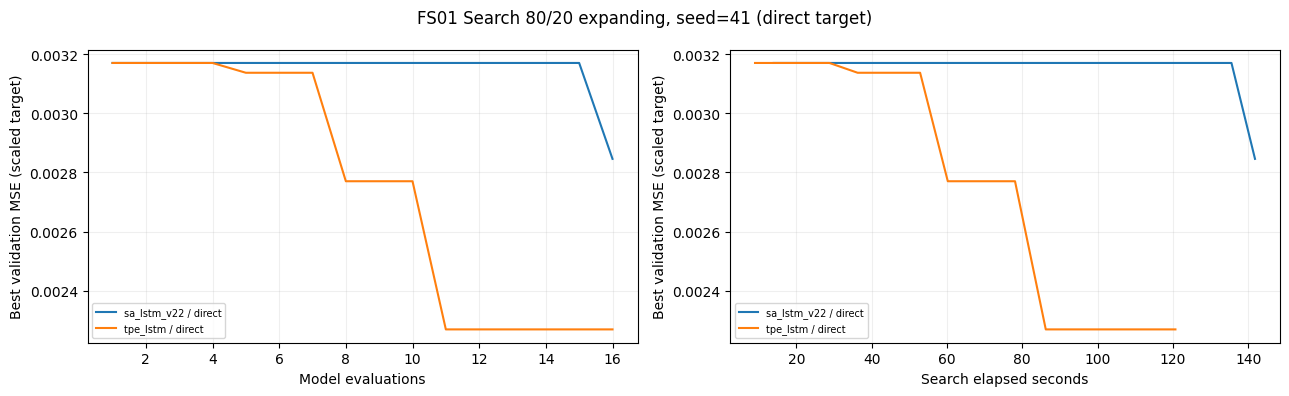

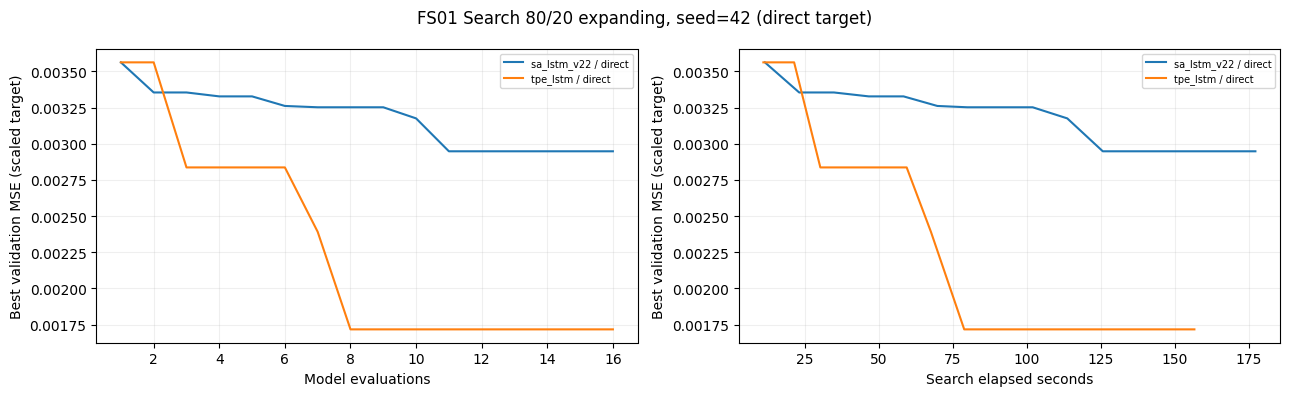

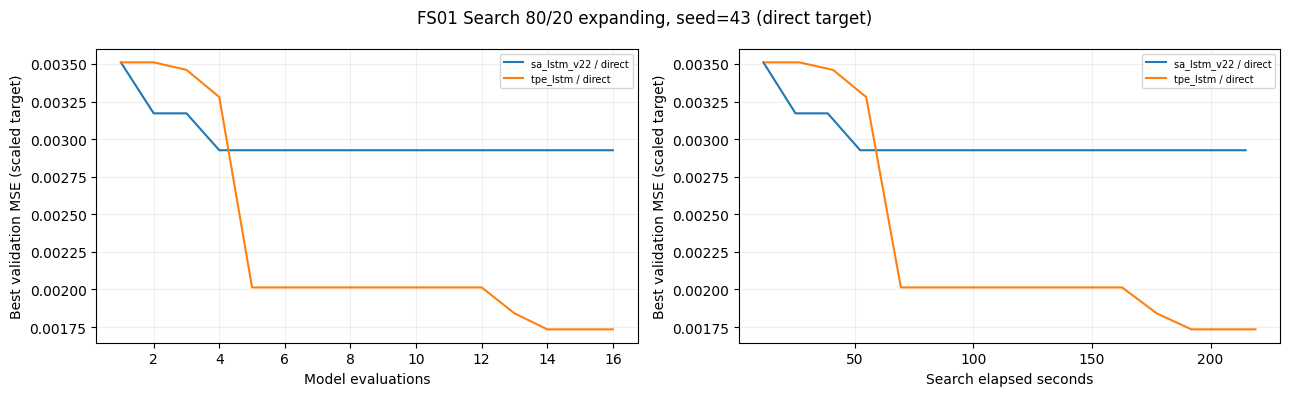

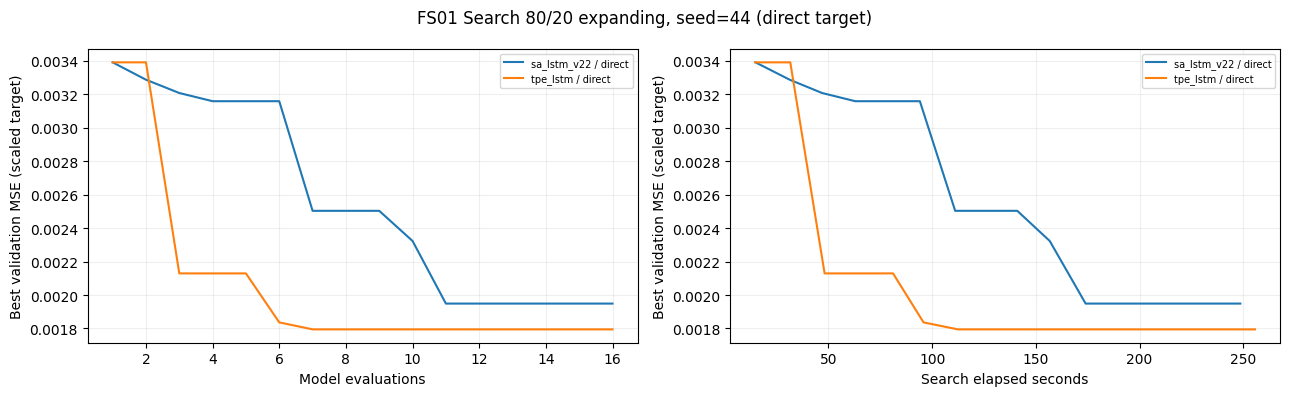

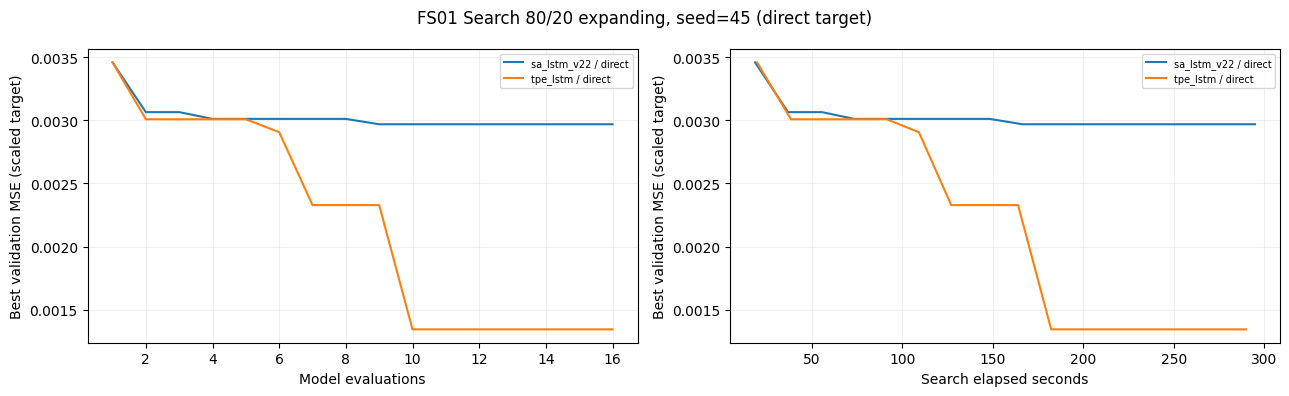

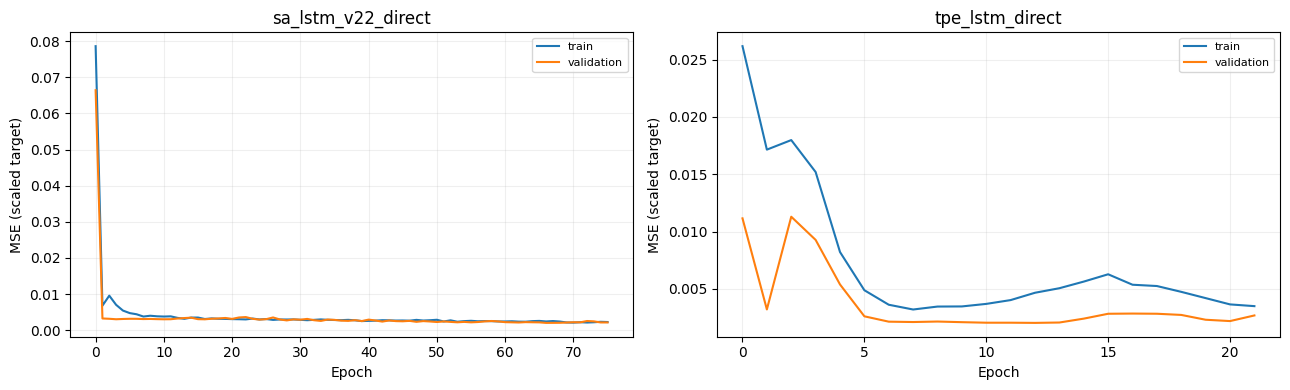

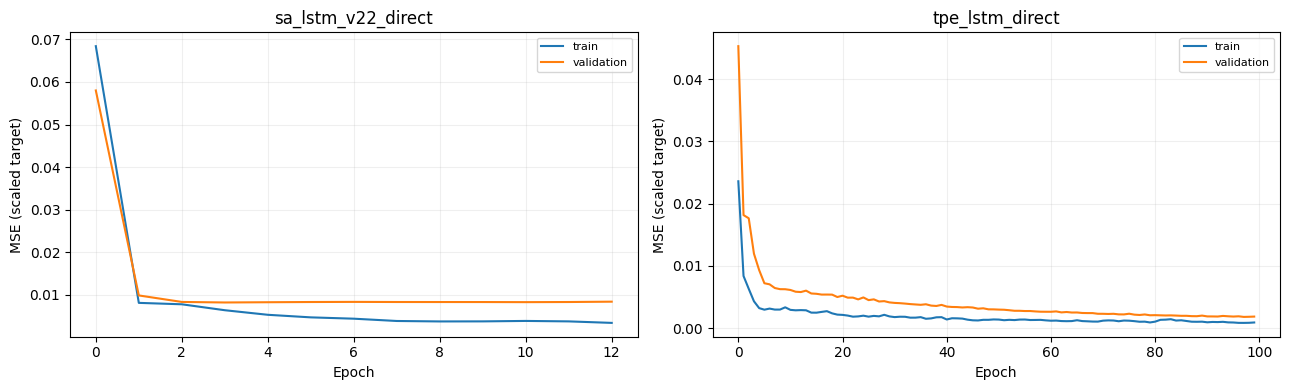

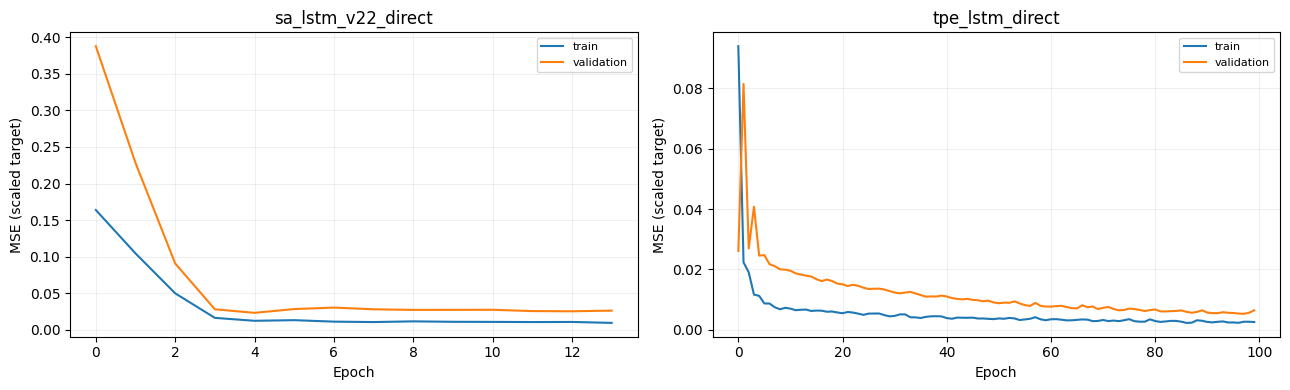

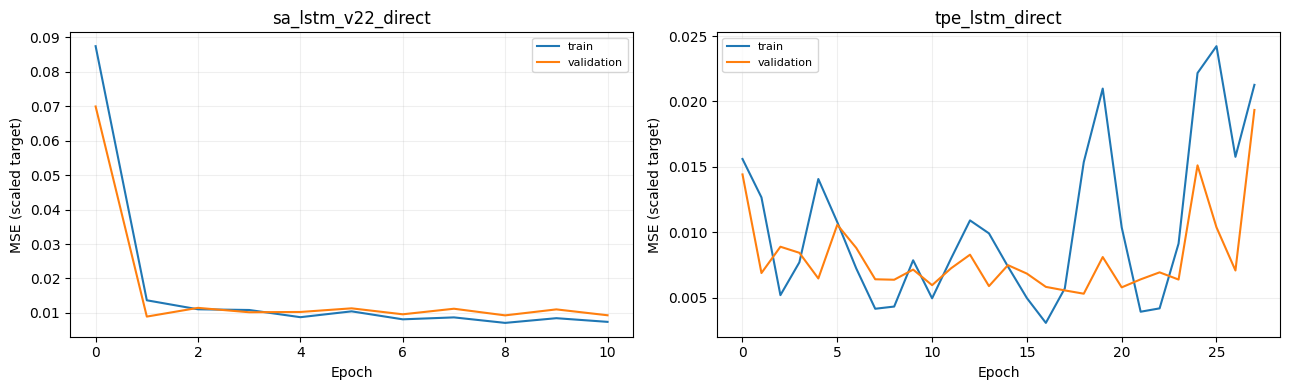

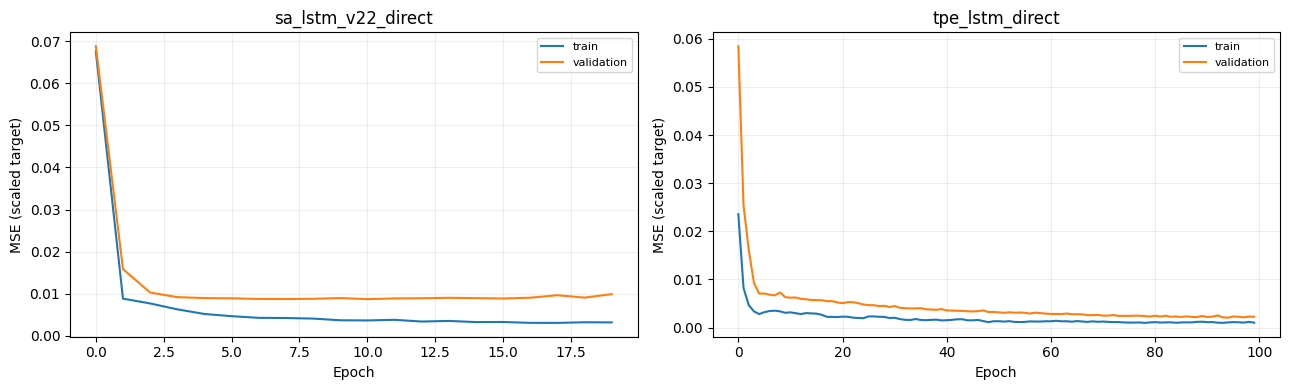

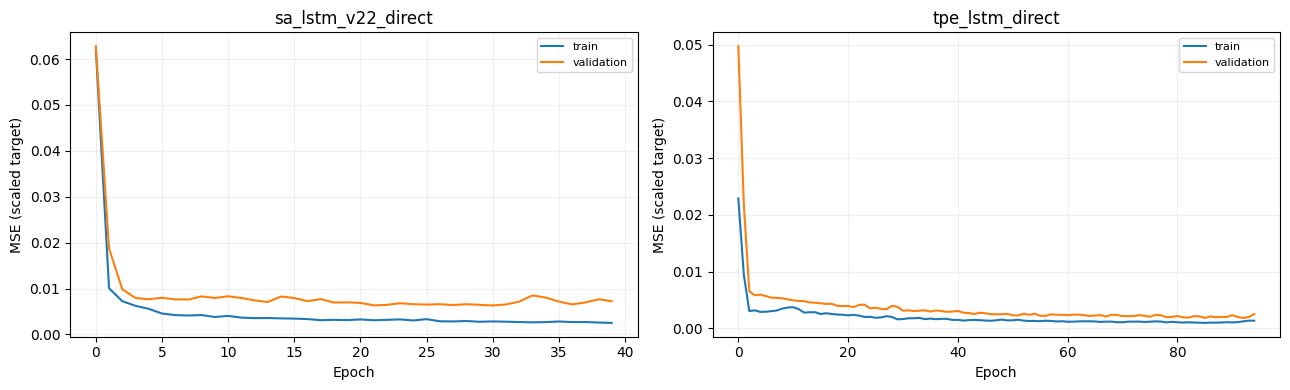

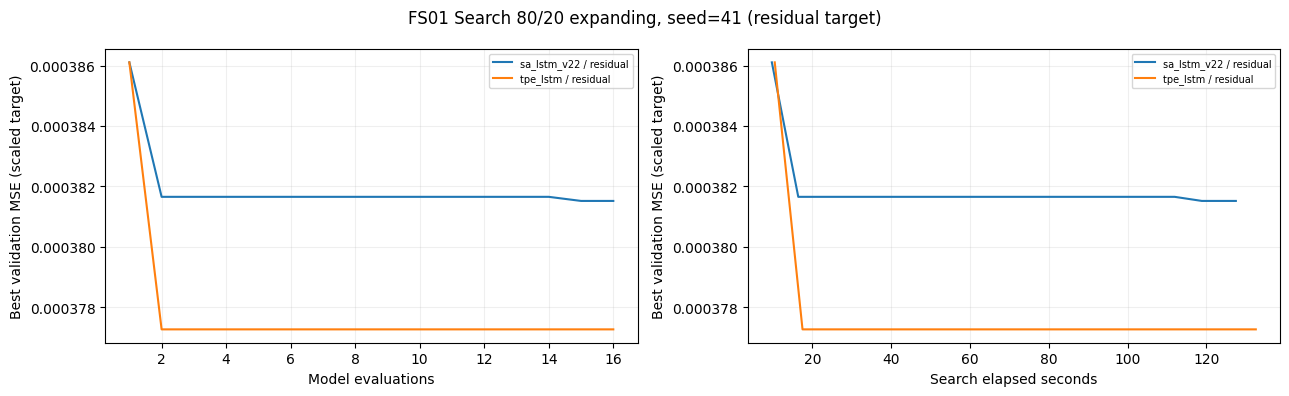

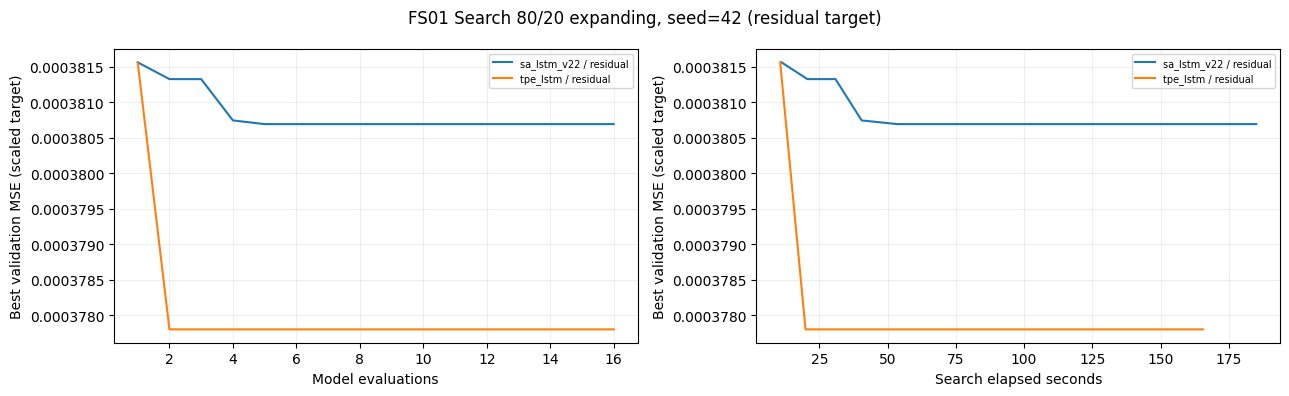

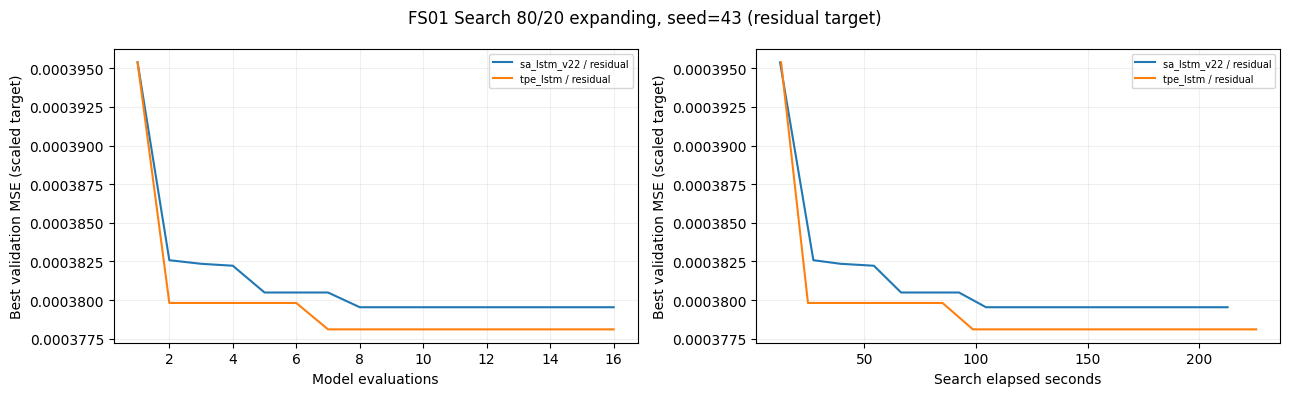

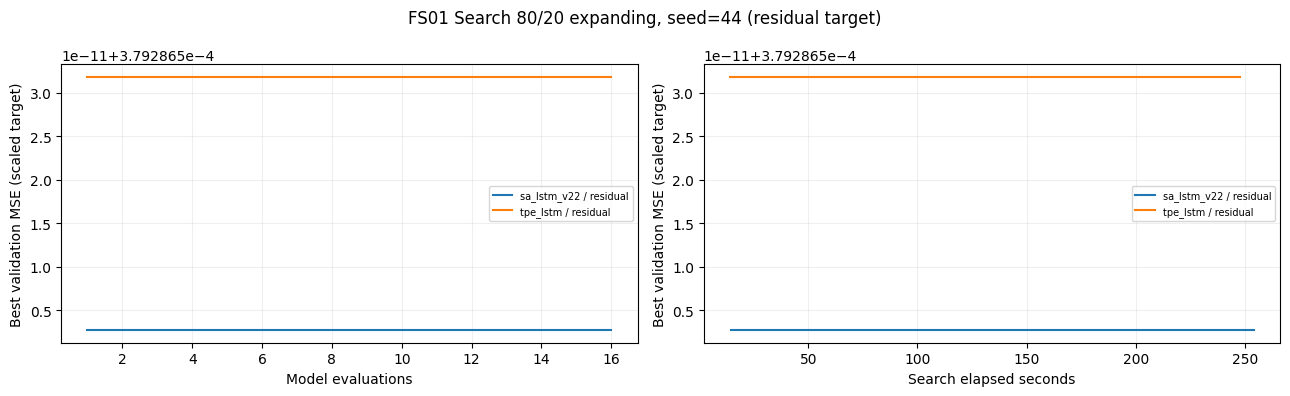

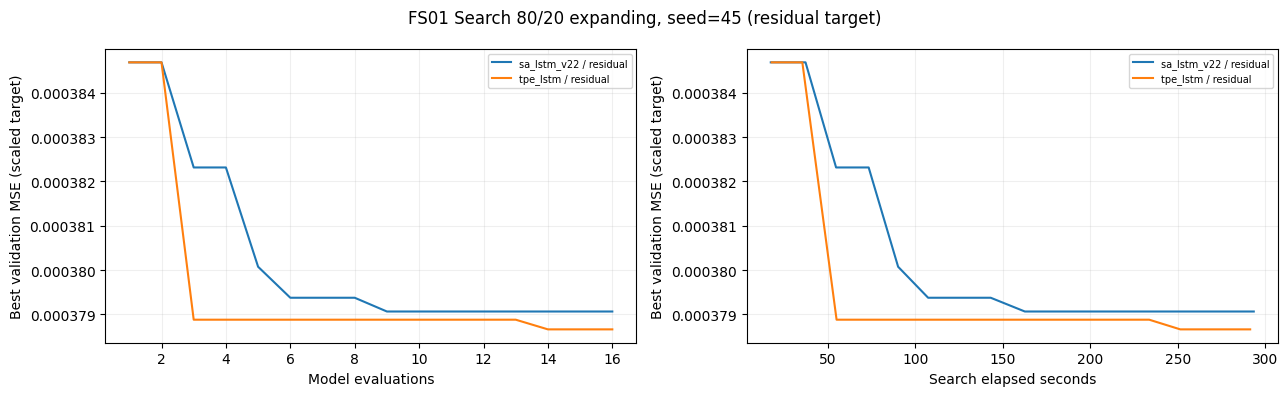

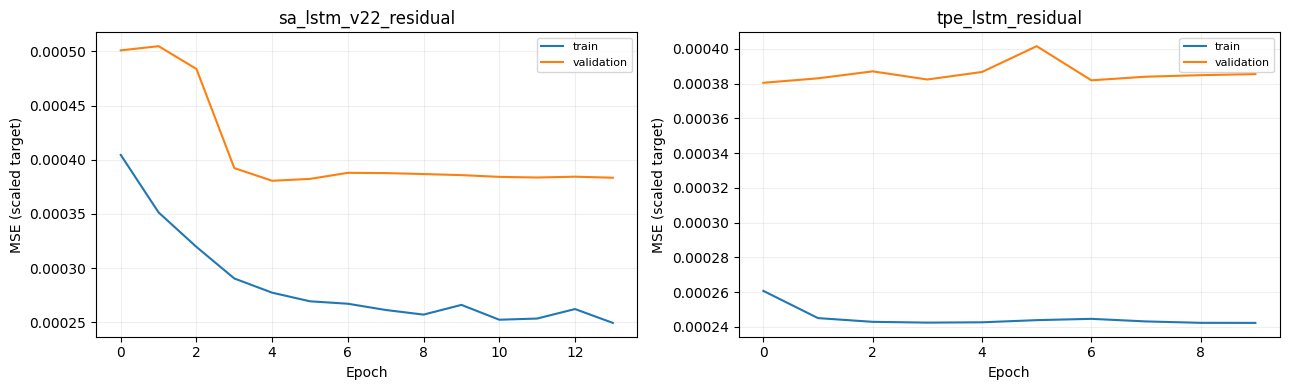

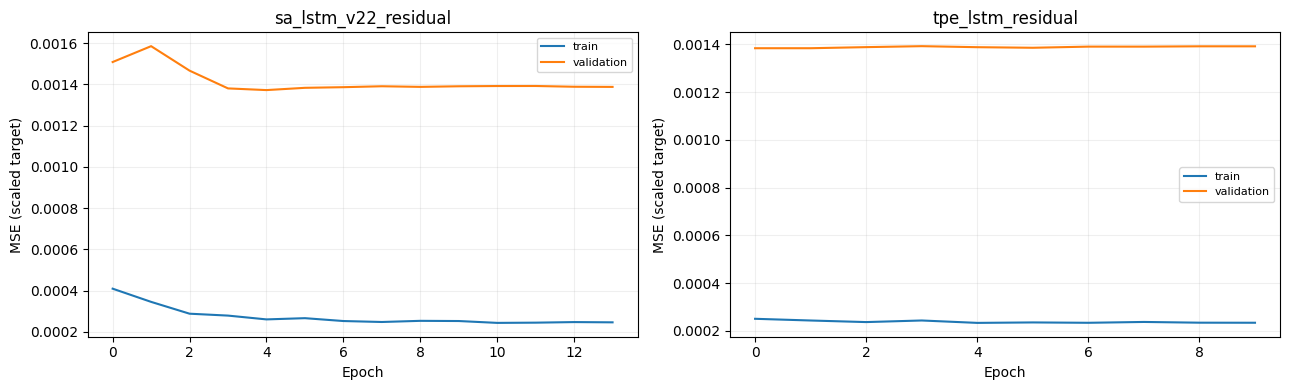

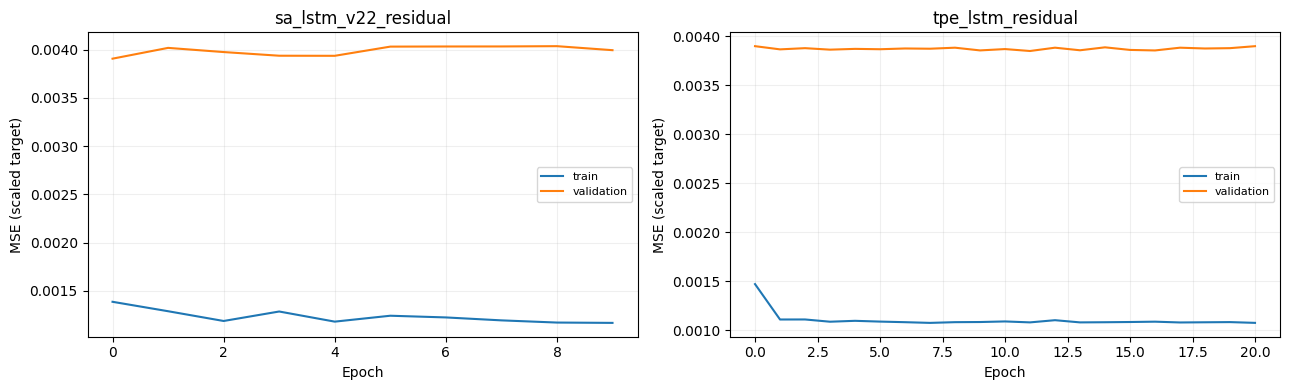

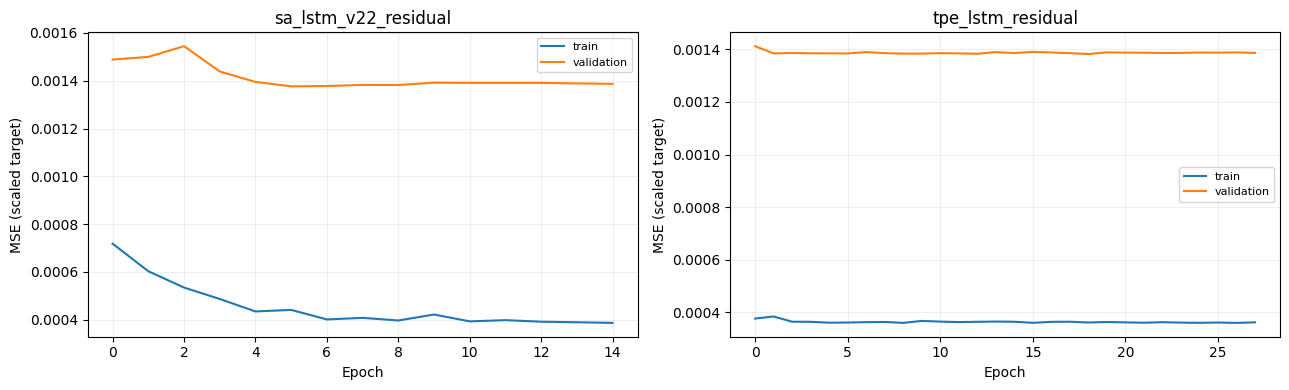

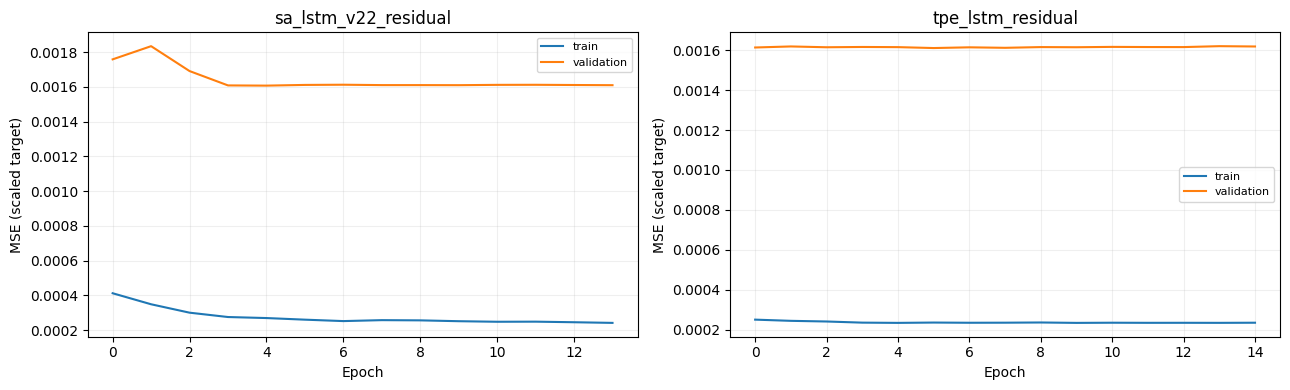

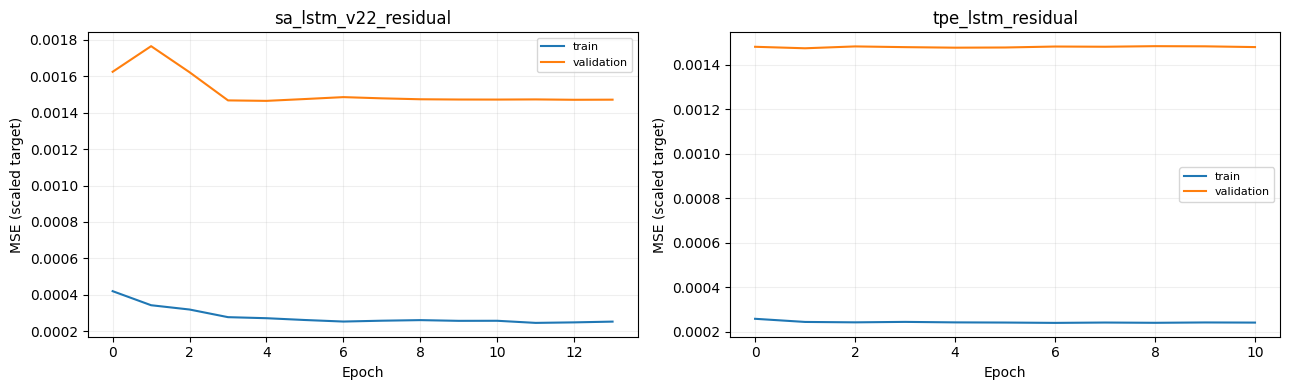

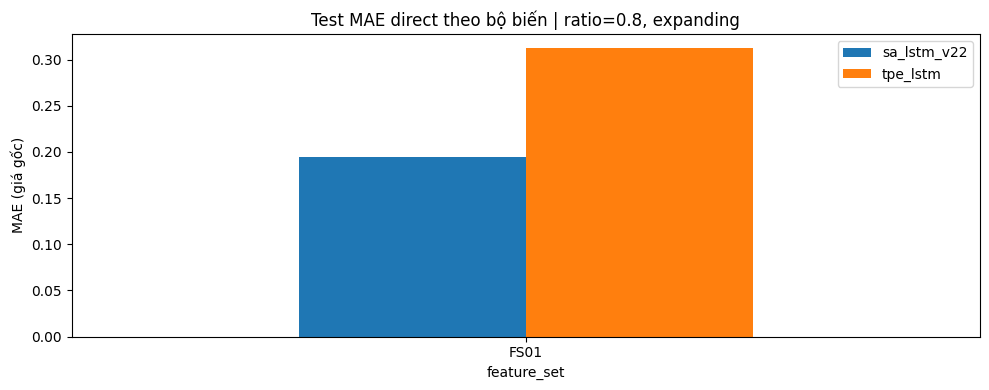

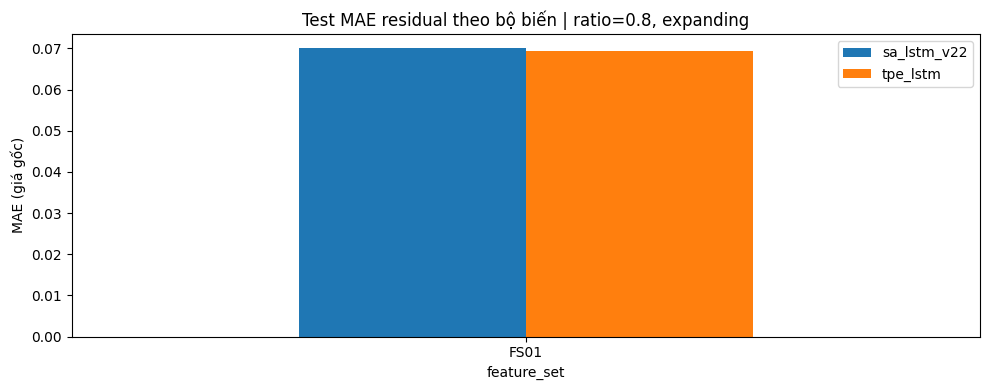

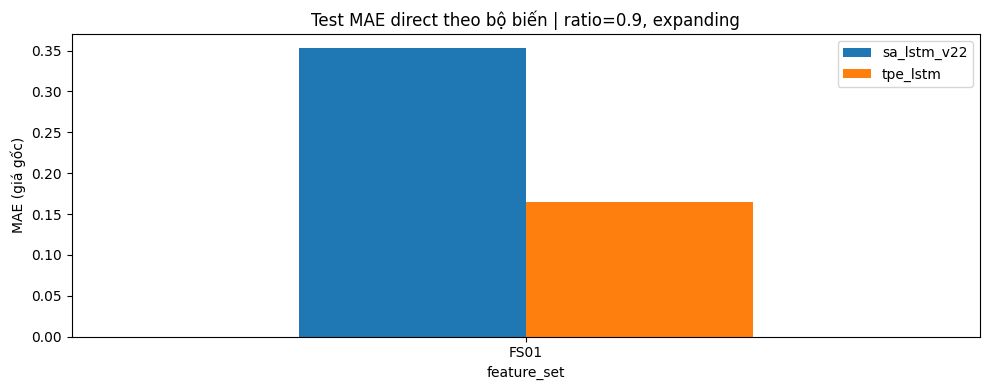

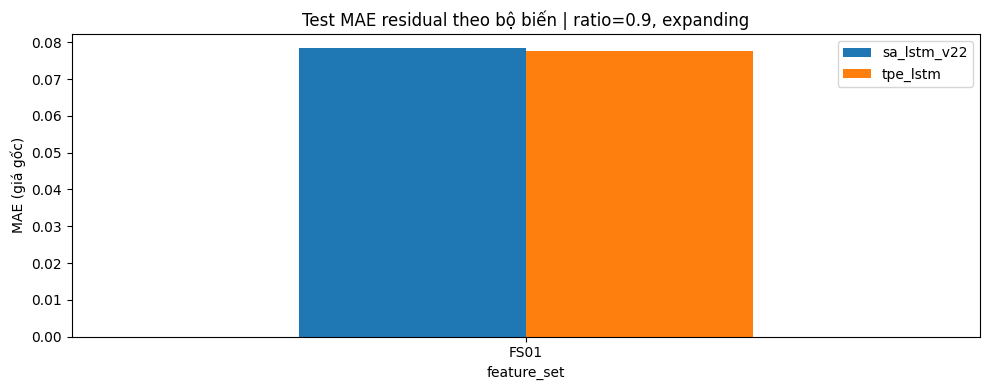

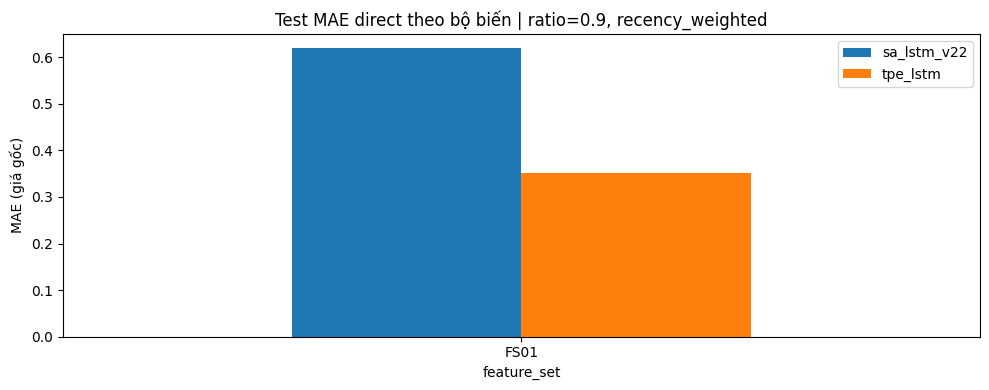

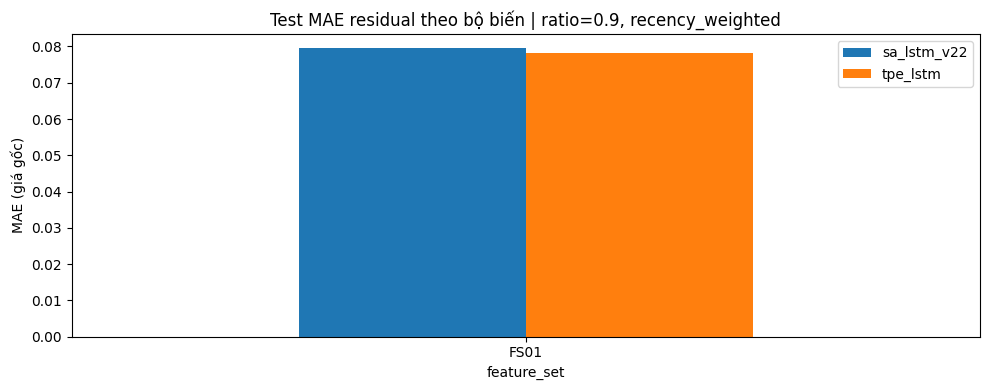

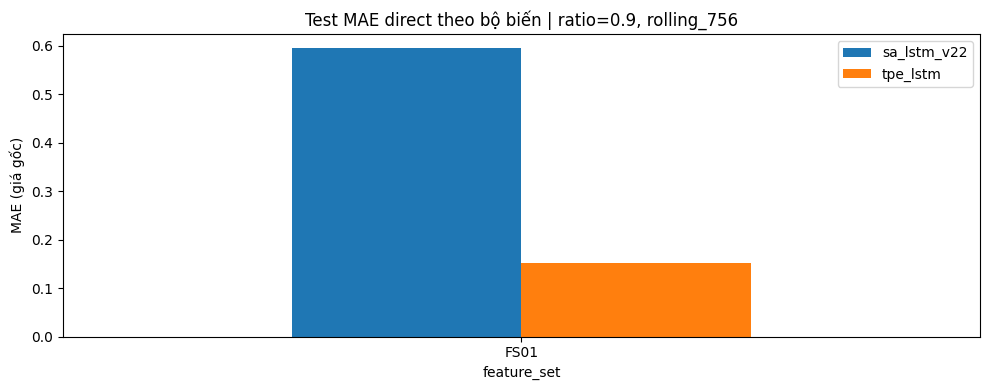

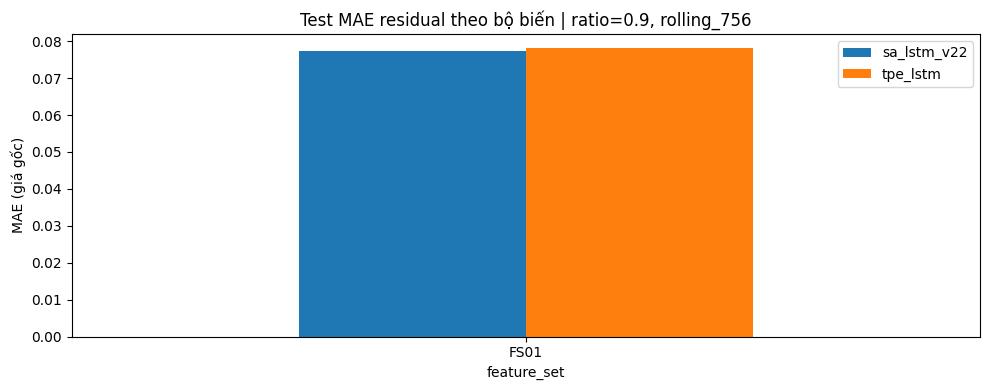

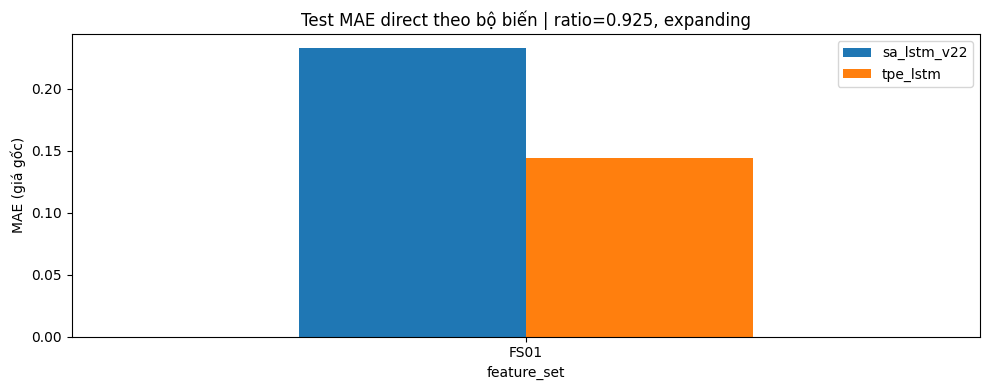

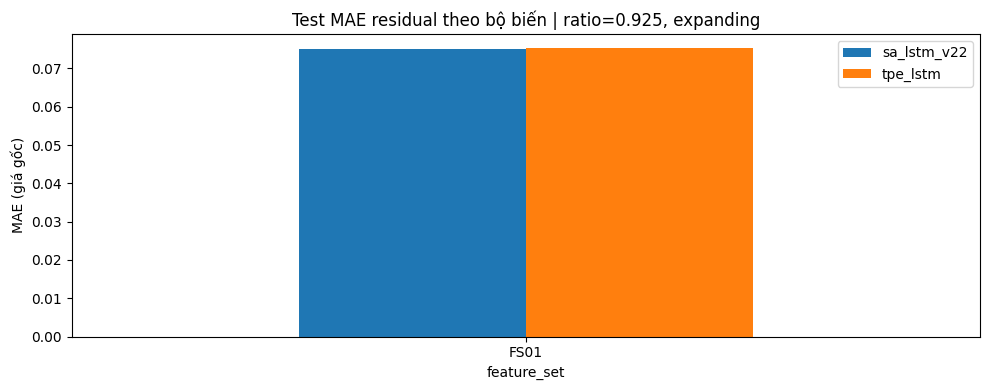

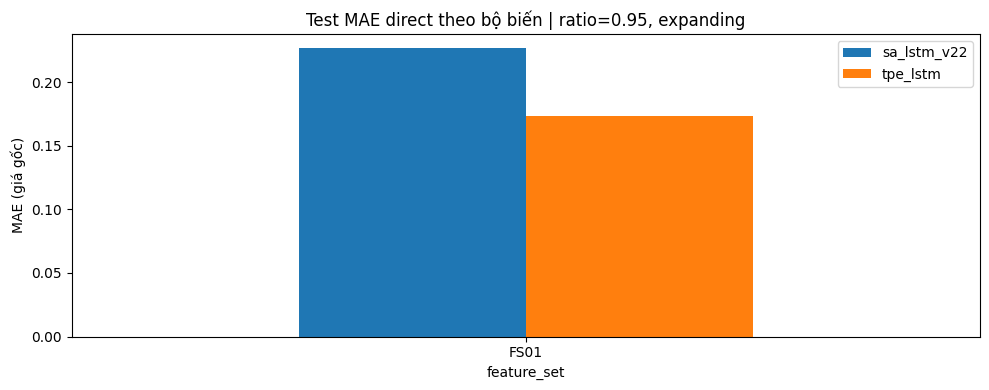

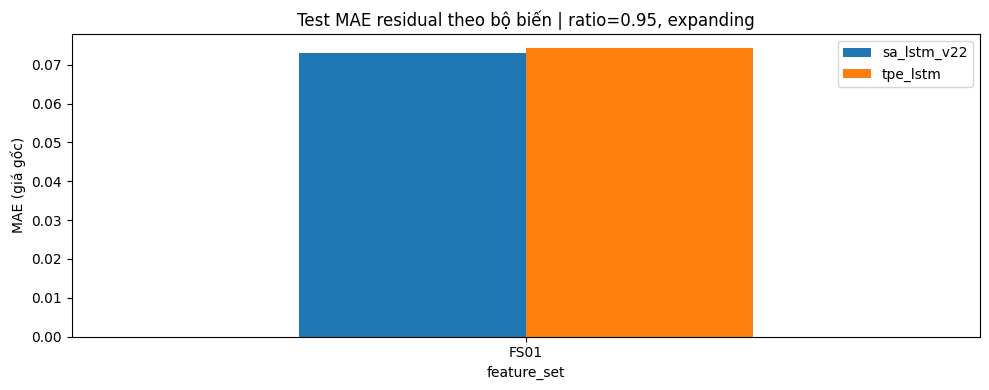

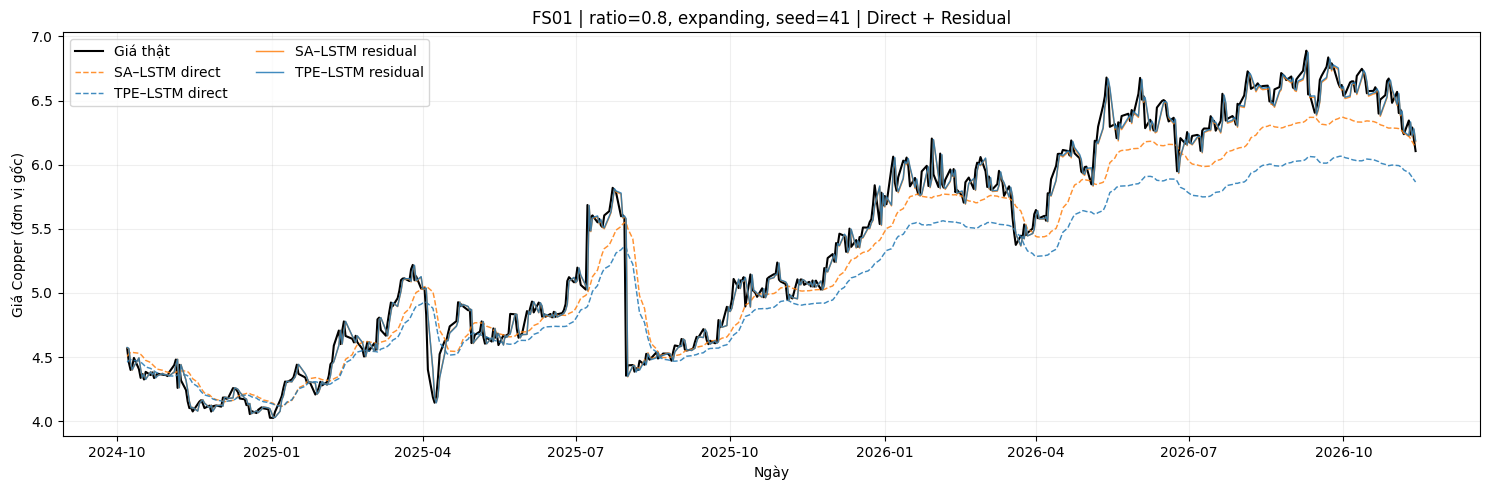

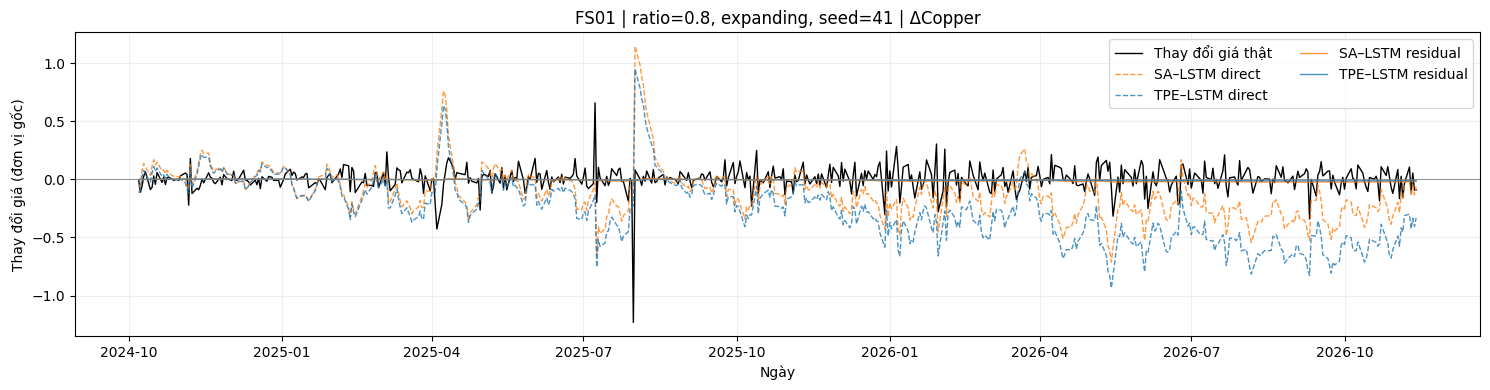

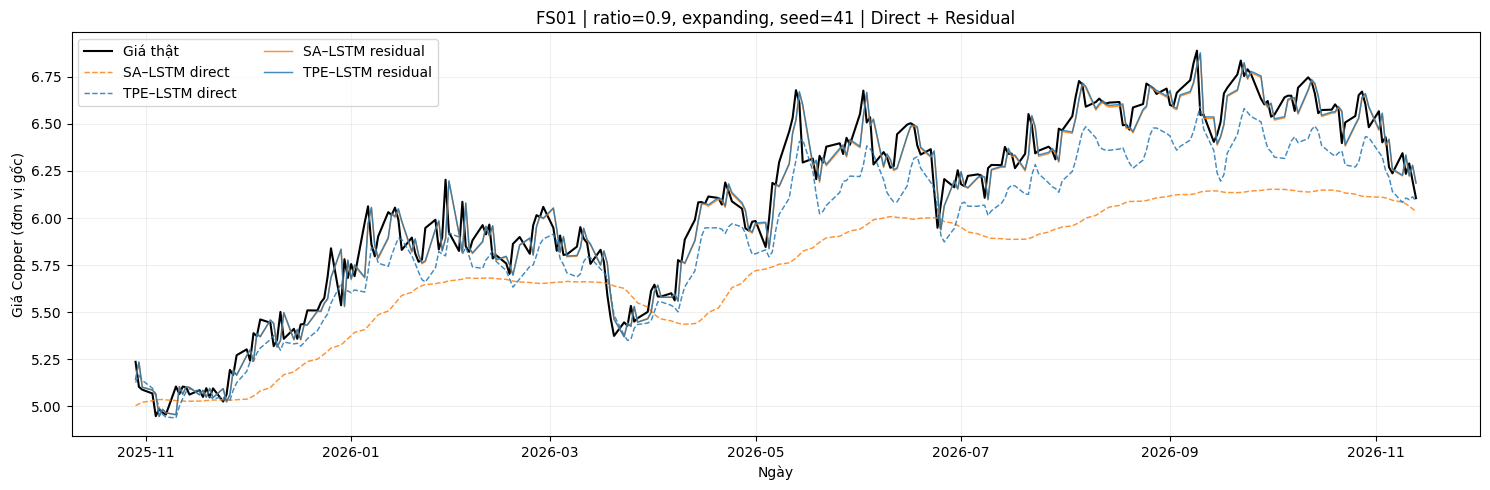

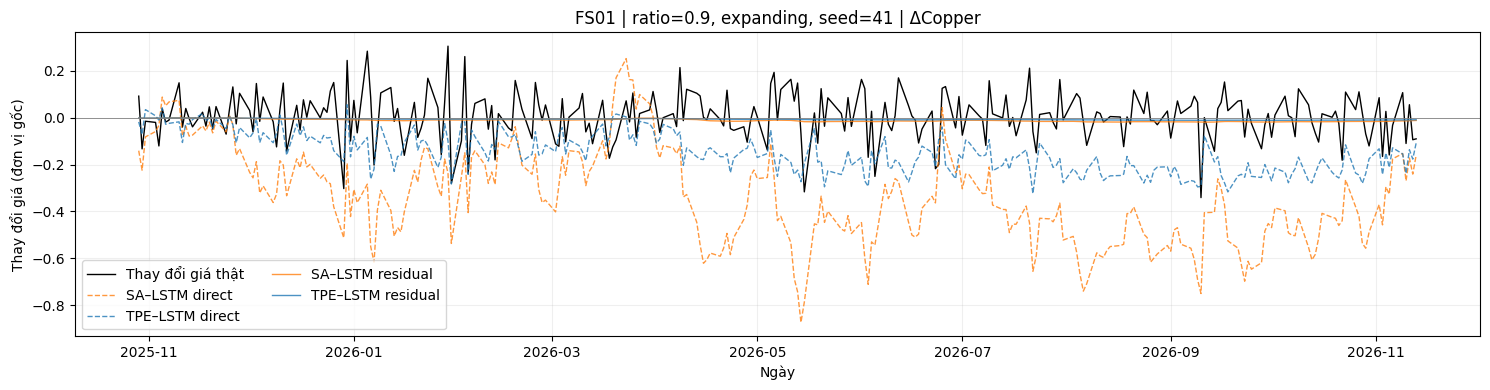

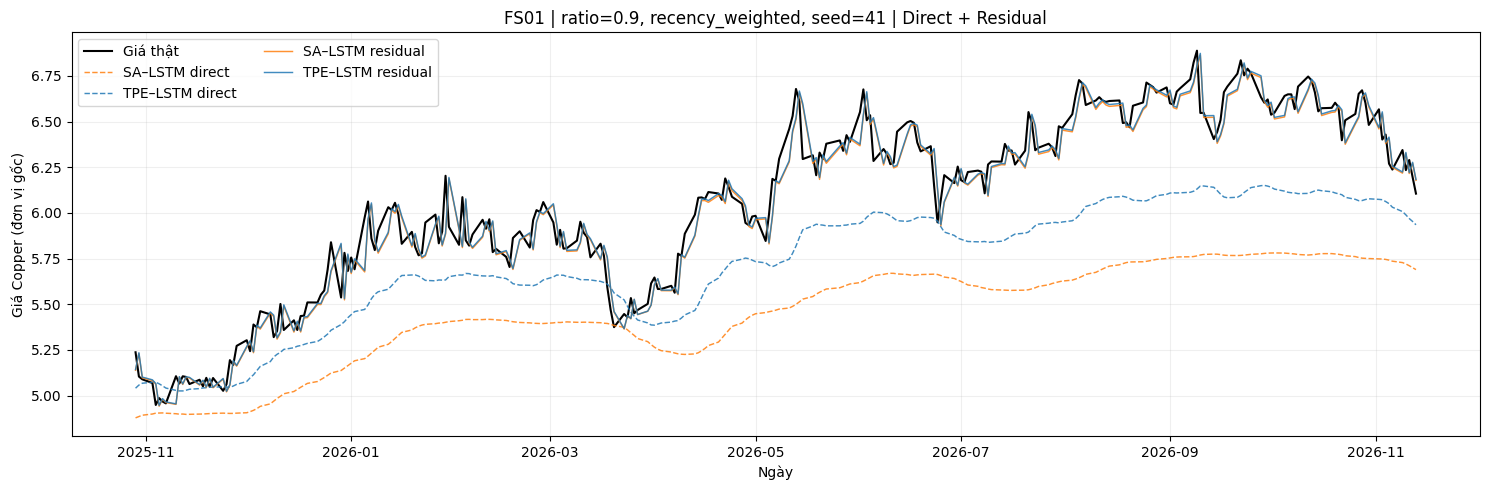

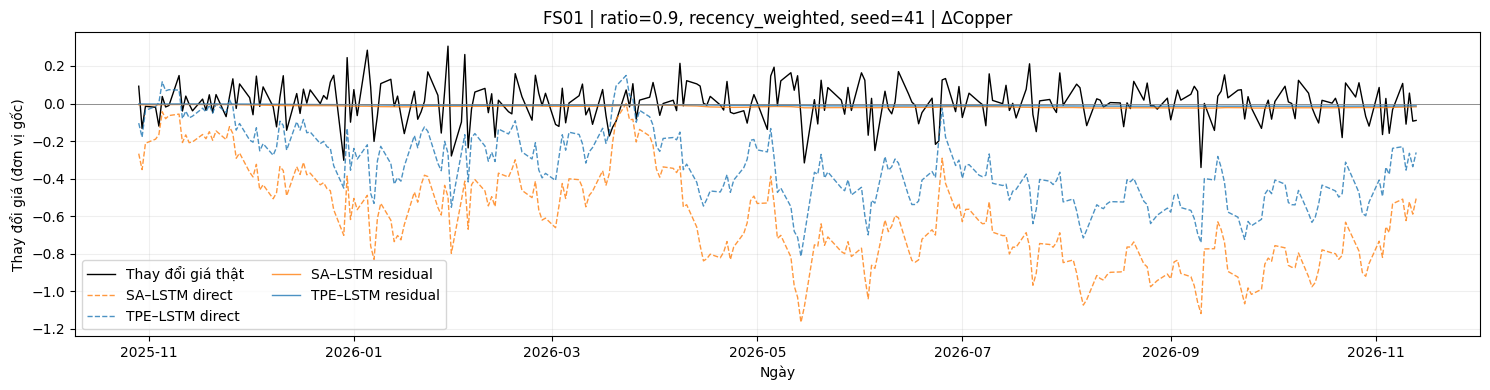

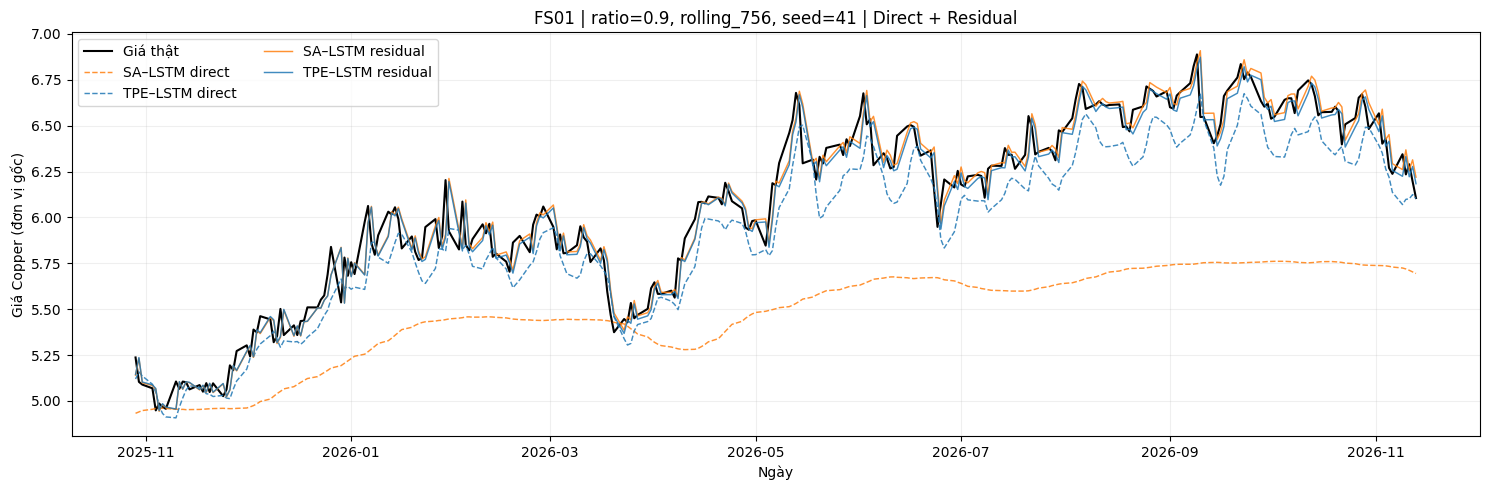

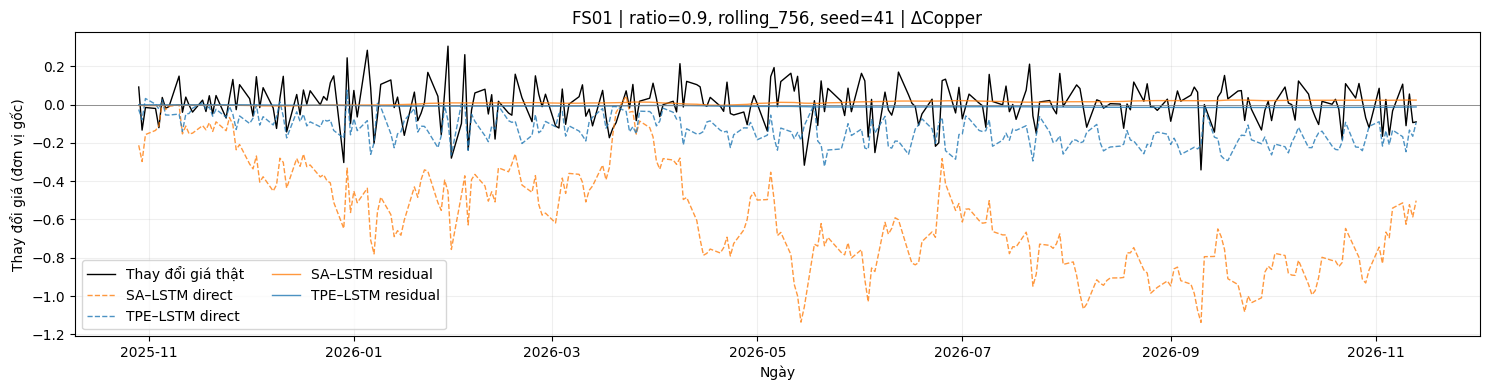

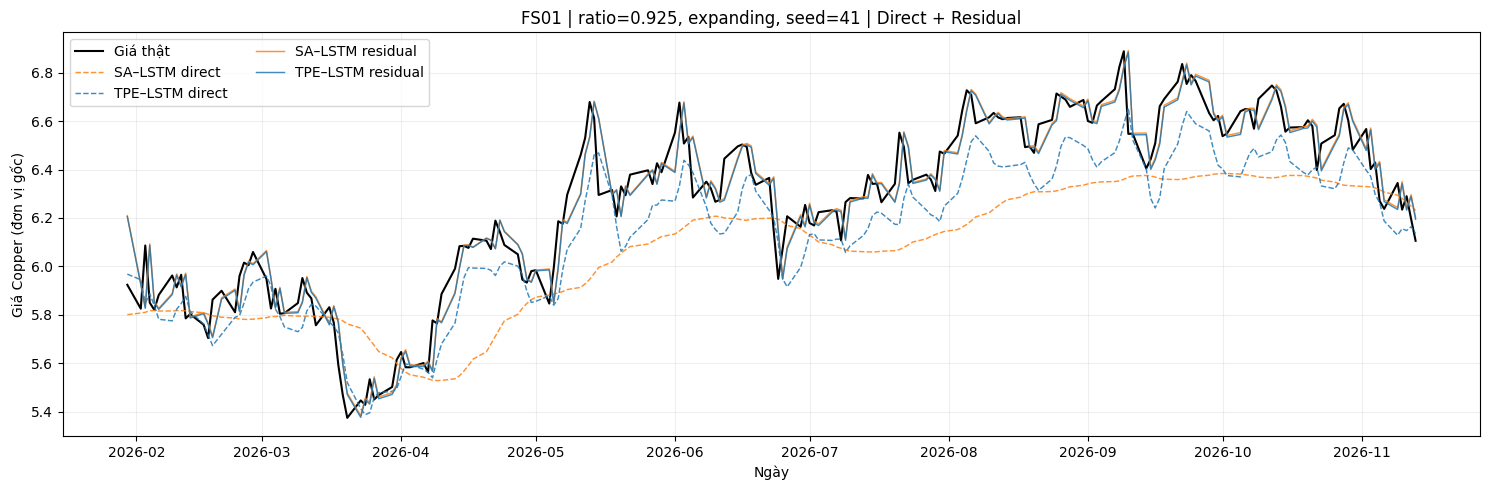

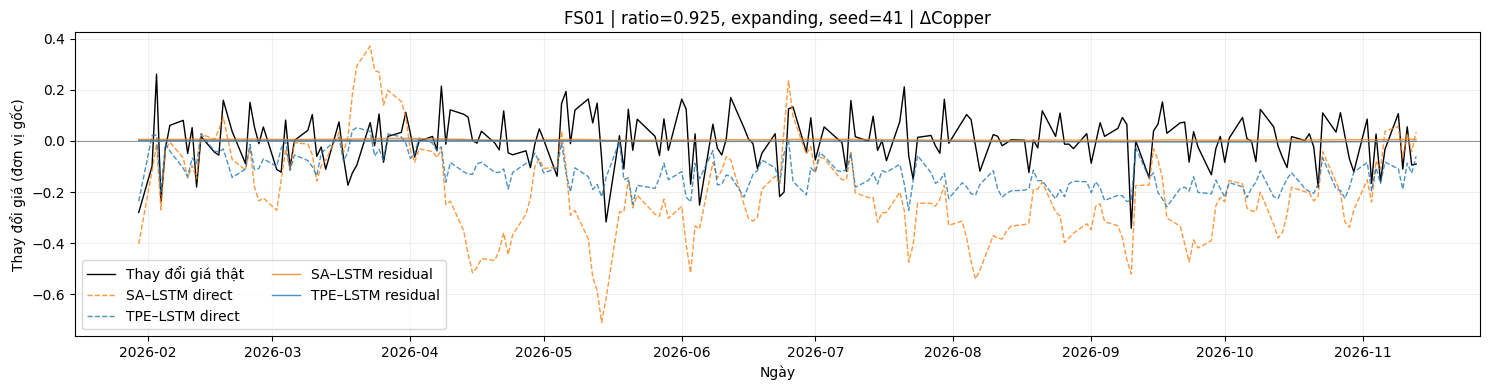

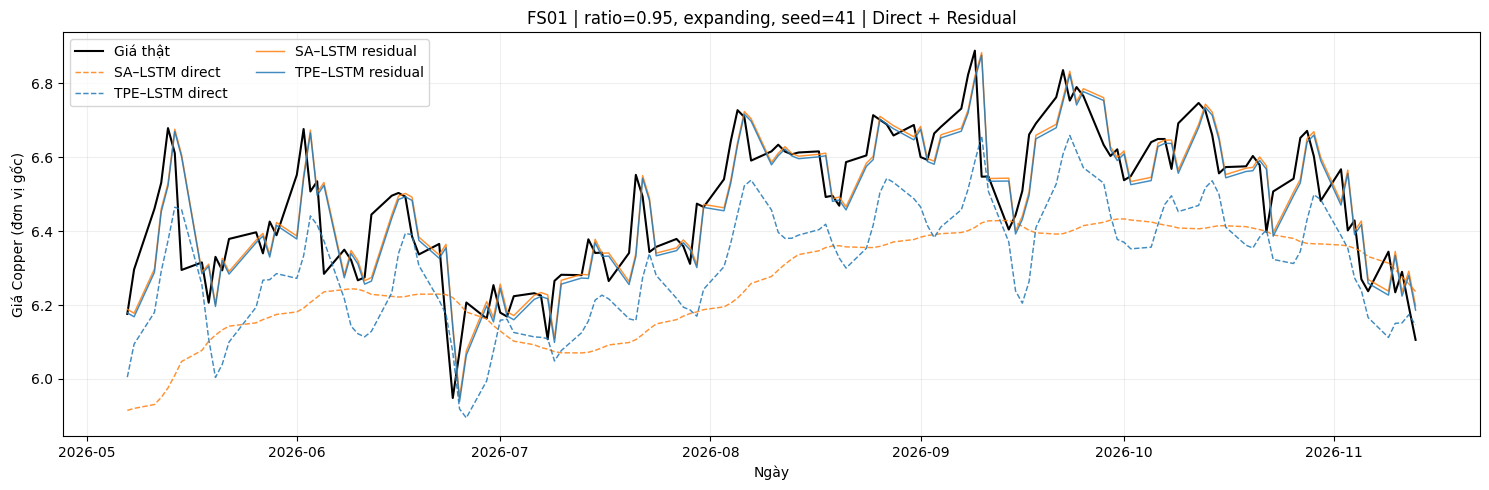

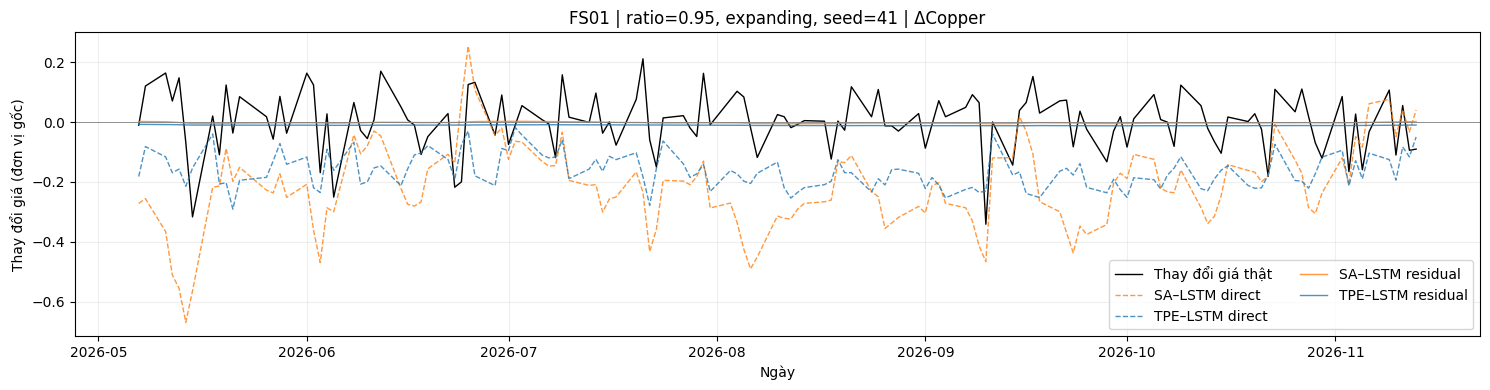

Đã tạo 12 hình ghép tại: /kaggle/working/copper_sa_tpe_FS01_direct_residual_seeds41_45/20261126T115315759532Z/merged_figures


In [16]:
for feature_set in ACTIVE_FEATURE_SETS:
    plot_dir=OUT/feature_set/'figures';plot_dir.mkdir(parents=True,exist_ok=True)
    for forecast_mode in FORECAST_MODES:
        mode_labels=[f'{method}_{forecast_mode}' for method in BASE_METHODS]
        for seed in SEEDS:
            fig,axs=plt.subplots(1,2,figsize=(13,4))
            for (mode,method),g in search_trials[(search_trials.forecast_mode==forecast_mode)&(search_trials.seed==seed)&(search_trials.feature_set==feature_set)].groupby(['forecast_mode','method']):
                g=g.sort_values('trial');label=f'{method} / {mode}'
                axs[0].plot(g.trial,g.best_val_mse_scaled,label=label)
                axs[1].plot(g.elapsed_seconds,g.best_val_mse_scaled,label=label)
            for ax in axs:
                ax.set_ylabel('Best validation MSE (scaled target)');ax.legend(fontsize=7);ax.grid(alpha=.2)
            axs[0].set_xlabel('Model evaluations');axs[1].set_xlabel('Search elapsed seconds')
            fig.suptitle(f'{feature_set} Search 80/20 expanding, seed={seed} ({forecast_mode} target)')
            fig.tight_layout();fig.savefig(plot_dir/f'{forecast_mode}_search_convergence_{seed}.png',dpi=150)
            plt.show();plt.close(fig)

        for ratio,scheme in JOBS:
            fig,axs=plt.subplots(1,2,figsize=(13,4))
            for ax,model_key in zip(axs.ravel(),mode_labels):
                recipe=next(r for r in final_models if r['feature_set']==feature_set and r['model_key']==model_key and
                            r['ratio']==ratio and r['scheme']==scheme and r['seed']==SEEDS[0])
                hist=pd.read_csv(Path(recipe['model_path']).with_name(f'{model_key}_loss.csv'))
                ax.plot(hist.loss,label='train');ax.plot(hist.val_loss,label='validation')
                ax.set(title=model_key,xlabel='Epoch',ylabel='MSE (scaled target)')
                ax.legend(fontsize=8);ax.grid(alpha=.2)
            fig.tight_layout();fig.savefig(plot_dir/f'{forecast_mode}_loss_{ratio}_{scheme}.png',dpi=150)
            plt.show();plt.close(fig)


for (ratio,scheme,forecast_mode),part in results_df[results_df.seed==SEEDS[0]].groupby(['ratio','scheme','forecast_mode']):
    table=part.pivot(index='feature_set',columns='method',values='mae').reindex(ACTIVE_FEATURE_SETS)
    ax=table.plot.bar(figsize=(10,4),rot=0)
    ax.set(title=f'Test MAE {forecast_mode} theo bộ biến | ratio={ratio}, {scheme}',ylabel='MAE (giá gốc)')
    ax.legend();ax.figure.tight_layout()
    ax.figure.savefig(OUT/f'{forecast_mode}_feature_sets_mae_{ratio}_{scheme}.png',dpi=150)
    plt.show();plt.close(ax.figure)


def plot_direct_residual_together(predictions_df, output_dir, plot_seeds):
    required={'feature_set','ratio','scheme','seed','method','forecast_mode','Date','actual','pred'}
    missing=required-set(predictions_df.columns)
    if missing:raise ValueError(f'CSV thiếu cột: {sorted(missing)}')
    df=predictions_df.copy()
    df['Date']=pd.to_datetime(df['Date'],errors='raise')
    df['seed']=pd.to_numeric(df['seed'],errors='raise').astype(int)
    for c in ['actual','pred']:
        df[c]=pd.to_numeric(df[c],errors='raise')
        if not np.isfinite(df[c]).all():raise ValueError(f'{c} có giá trị không hữu hạn')
    missing_seeds=set(plot_seeds)-set(df.seed.unique())
    if missing_seeds:raise ValueError(f'Chưa có kết quả seeds {sorted(missing_seeds)}; sửa PLOT_SEEDS theo CSV.')
    styles={
        ('sa_lstm_v22','direct'):('SA–LSTM direct','tab:orange','--'),
        ('tpe_lstm','direct'):('TPE–LSTM direct','tab:blue','--'),
        ('sa_lstm_v22','residual'):('SA–LSTM residual','tab:orange','-'),
        ('tpe_lstm','residual'):('TPE–LSTM residual','tab:blue','-'),
    }
    output_dir=Path(output_dir);output_dir.mkdir(parents=True,exist_ok=True)
    saved=[]
    for (fs,ratio,scheme,seed),part in df[df.seed.isin(plot_seeds)].groupby(['feature_set','ratio','scheme','seed']):
        keys=set(zip(part.method,part.forecast_mode))
        missing_models=set(styles)-keys
        if missing_models:
            raise ValueError(f'{fs}, ratio={ratio}, {scheme}, seed={seed}: thiếu {sorted(missing_models)}. '
                             'Cần CSV đã có kết quả của cả direct và residual; vẽ lại không sinh thêm dự báo.')
        groups={key:part[(part.method==key[0])&(part.forecast_mode==key[1])].sort_values('Date') for key in styles}
        ref=next(iter(groups.values()))
        for key,g in groups.items():
            if g.Date.duplicated().any():raise ValueError(f'Trùng ngày: {fs}, {key}')
            if not np.array_equal(ref.Date.to_numpy(),g.Date.to_numpy()) or not np.allclose(ref.actual,g.actual):
                raise ValueError(f'Các nhánh không cùng ngày/giá thật: {fs}, {key}')
        folder=output_dir/fs;folder.mkdir(parents=True,exist_ok=True)
        tag=f'{ratio:g}_{scheme}_seed{seed}'
        fig,ax=plt.subplots(figsize=(15,5))
        ax.plot(ref.Date,ref.actual,color='black',label='Giá thật',linewidth=1.5)
        for key,(label,color,linestyle) in styles.items():
            g=groups[key]
            ax.plot(g.Date,g.pred,label=label,color=color,linestyle=linestyle,linewidth=1.05,alpha=.85)
        ax.set(title=f'{fs} | ratio={ratio:g}, {scheme}, seed={seed} | Direct + Residual',
               xlabel='Ngày',ylabel='Giá Copper (đơn vị gốc)')
        ax.legend(ncol=2);ax.grid(alpha=.2);fig.tight_layout()
        path=folder/f'merged_price_{tag}.png';fig.savefig(path,dpi=160);saved.append(path)
        plt.show();plt.close(fig)
        # Các thống kê delta đã được tạo khi đánh giá; không chạy lại mô hình.
        if {'actual_delta','pred_delta'} <= set(part.columns):
            fig,ax=plt.subplots(figsize=(15,4))
            ax.plot(ref.Date,ref.actual_delta,color='black',label='Thay đổi giá thật',linewidth=1)
            for key,(label,color,linestyle) in styles.items():
                g=groups[key]
                ax.plot(g.Date,g.pred_delta,label=label,color=color,linestyle=linestyle,linewidth=1,alpha=.8)
            ax.axhline(0,color='gray',linewidth=.6)
            ax.set(title=f'{fs} | ratio={ratio:g}, {scheme}, seed={seed} | ΔCopper',
                   xlabel='Ngày',ylabel='Thay đổi giá (đơn vị gốc)')
            ax.legend(ncol=2);ax.grid(alpha=.2);fig.tight_layout()
            path=folder/f'merged_delta_{tag}.png';fig.savefig(path,dpi=160);saved.append(path)
            plt.show();plt.close(fig)
    return saved

PLOT_SEEDS=[41]  # Đổi thành [41,42,43,44,45] nếu muốn vẽ từng seed.
merged_files=plot_direct_residual_together(predictions_df,OUT/'merged_figures',PLOT_SEEDS)
print(f'Đã tạo {len(merged_files)} hình ghép tại: {OUT / "merged_figures"}')


## 8. Kết quả

- `manifest.json`: định nghĩa đầy đủ các bộ biến đang chạy, dữ liệu, ngân sách và seeds.
- `metrics_by_run.csv`: 120 dòng kết quả của FS01 và seeds 41–45; có cột feature_set.
- `paired_comparison_SA_vs_TPE_by_mode.csv`: 60 cặp SA/TPE cùng bộ/ratio/scheme/seed.
- `paired_comparison_residual_vs_direct.csv`: chênh lệch residual − direct trên cùng bộ/split/sampler/seed.
- `feature_set_comparison_mae.csv`: bảng MAE của FS01 theo ratio/scheme/seed/target.
- `search_comparison.csv`, `all_search_trials.csv`, `locked_best_hyperparameters.json`: search riêng cho từng bộ/target.
- `data_split_summary.csv`, `final_training.csv`, `test_predictions.csv`, `summary_mean_std.csv` và model/scalers/loss/figures theo thư mục FSxx.
- ZIP chứa toàn bộ kết quả. `summary_mean_std.csv` báo mean/std của 5 seeds cho từng bộ/ratio/scheme/target/phương pháp. Kết quả quick chỉ kiểm tra luồng.


In [17]:
zip_path=OUT.parent/(OUT.name+'_results.zip')
with zipfile.ZipFile(zip_path,'w',compression=zipfile.ZIP_DEFLATED) as z:
    for file in sorted(OUT.rglob('*')):
        if file.is_file():z.write(file,arcname=str(file.relative_to(OUT)))
print('Results:',OUT)
print('ZIP:',zip_path)
display(FileLink(str(zip_path)))


Results: /kaggle/working/copper_sa_tpe_FS01_direct_residual_seeds41_45/20261126T115315759532Z
ZIP: /kaggle/working/copper_sa_tpe_FS01_direct_residual_seeds41_45/20261126T115315759532Z_results.zip


/kaggle/working/copper_sa_tpe_FS01_direct_residual_seeds41_45/20261126T115315759532Z_results.zip